#### Dicionário Completo de Dados do ENEM (76 Features)

Abaixo está a catalogação de todas as colunas disponíveis na nossa amostra após a unificação dos dados. As colunas estão agrupadas por suas categorias lógicas.

**1. Dados do Participante (Demográficos e Inscrição)**
| Coluna | Tipo (Pandas) | Significado |
| :--- | :--- | :--- |
| **`NU_INSCRICAO`** | `int64` | Número de inscrição único do participante (usado apenas como ID). |
| **`NU_ANO`** | `int64` | Ano de realização do exame. |
| **`TP_FAIXA_ETARIA`** | `int64` | Faixa etária do candidato (ex: 1 = Menor de 17 anos...). |
| **`TP_SEXO`** | `object` | Sexo do participante ('M' ou 'F'). |
| **`TP_ESTADO_CIVIL`** | `int64` | Estado Civil do participante (0 = Não informado, 1 = Solteiro, etc). |
| **`TP_COR_RACA`** | `int64` | Cor/raça declarada (1 = Branca, 2 = Preta, 3 = Parda, 4 = Amarela, 5 = Indígena). |
| **`TP_NACIONALIDADE`** | `int64` | Nacionalidade (1 = Brasileiro, 2 = Brasileiro Naturalizado, etc). |
| **`TP_ST_CONCLUSAO`** | `int64` | Situação de conclusão do Ensino Médio (ex: 1 = Já concluí, 2 = Concluirei neste ano). |
| **`TP_ANO_CONCLUIU`** | `int64` | Ano de conclusão do Ensino Médio (0 = Não informado, 1 = 2022, 2 = 2021...). |
| **`IN_TREINEIRO`** | `int64` | Indica se o inscrito fez a prova apenas para treinar (1 = Sim, 0 = Não). |

<br>

 **2. Dados da Escola do Ensino Médio**

| Coluna | Tipo (Pandas) | Significado |
| :--- | :--- | :--- |
| **`TP_ESCOLA`** | `int64` | Tipo de escola do Ensino Médio (1 = Não Respondeu, 2 = Pública, 3 = Privada). |
| **`TP_ENSINO`** | `float64` | Tipo de instituição que concluiu ou concluirá (1 = Ensino Regular, 2 = Especial...). |
| **`CO_MUNICIPIO_ESC`** | `float64` | Código IBGE do município da escola. |
| **`NO_MUNICIPIO_ESC`** | `object` | Nome do município da escola. |
| **`CO_UF_ESC`** | `float64` | Código IBGE do estado (UF) da escola. |
| **`SG_UF_ESC`** | `object` | Sigla da Unidade da Federação da escola. |
| **`TP_DEPENDENCIA_ADM_ESC`** | `float64` | Dependência administrativa da escola (1 = Federal, 2 = Estadual, 3 = Municipal, 4 = Privada). |
| **`TP_LOCALIZACAO_ESC`** | `float64` | Localização da escola (1 = Urbana, 2 = Rural). |
| **`TP_SIT_FUNC_ESC`** | `float64` | Situação de funcionamento da escola (1 = Em Atividade, 2 = Paralisada...). |

<br>

 **3. Local de Aplicação da Prova**
| Coluna | Tipo (Pandas) | Significado |
| :--- | :--- | :--- |
| **`CO_MUNICIPIO_PROVA`** | `int64` | Código IBGE do município da aplicação da prova. |
| **`NO_MUNICIPIO_PROVA`** | `object` | Nome do município da aplicação da prova. |
| **`CO_UF_PROVA`** | `int64` | Código IBGE da UF da aplicação da prova. |
| **`SG_UF_PROVA`** | `object` | Sigla da Unidade da Federação da aplicação da prova. |

<br>
 **4. Presença e Tipo de Prova**

| Coluna | Tipo (Pandas) | Significado |
| :--- | :--- | :--- |
| **`TP_PRESENCA_CN`** | `int64` | Presença na prova de Ciências da Natureza (0 = Faltou, 1 = Presente, 2 = Eliminado). |
| **`TP_PRESENCA_CH`** | `int64` | Presença na prova de Ciências Humanas (0 = Faltou, 1 = Presente, 2 = Eliminado). |
| **`TP_PRESENCA_LC`** | `int64` | Presença na prova de Linguagens e Códigos (0 = Faltou, 1 = Presente, 2 = Eliminado). |
| **`TP_PRESENCA_MT`** | `int64` | Presença na prova de Matemática (0 = Faltou, 1 = Presente, 2 = Eliminado). |
| **`CO_PROVA_CN`** | `float64` | Código do caderno de prova de Ciências da Natureza (ex: Azul, Amarelo). |
| **`CO_PROVA_CH`** | `float64` | Código do caderno de prova de Ciências Humanas. |
| **`CO_PROVA_LC`** | `float64` | Código do


Diferente de abordagens tradicionais que fixam a variável-alvo (target) a priori, este projeto adotará uma estratégia exploratória de múltiplos alvos (Multi-Target Exploration).

Como as notas das cinco áreas de conhecimento possuem naturezas distintas (vistas nas distribuições e correlações), a etapa de Engenharia de Features e Modelagem Inicial não irá pressupor um único alvo. Em vez disso, 8 variáveis-alvo distintas serão construídas (notas individuais, médias parciais e média geral).

Modelos de baseline (Random Forest) serão treinados simultaneamente para todos os 8 alvos. O objetivo será comparar a estabilidade da importância das variáveis (Feature Importance) através dos diferentes alvos. A escolha do target definitivo do modelo final será empírica, baseada naquele que apresentar a melhor capacidade de extração de sinal a partir das variáveis sociodemográficas e escolares analisadas nesta EDA.

#### Import de bibliotecas

In [267]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#### Biblioteca de Funcoes

In [268]:
def analisa_mnar(df, coluna, label_informado, label_nao_informado):
    """
    Analisa o padrão de ausência (MNAR) de uma coluna em relação 
    ao status de conclusão do ensino médio (TP_ST_CONCLUSAO).
    """
    # Seleciona apenas as colunas necessárias para economizar memória
    temp_df = df[['TP_ST_CONCLUSAO', coluna]].copy()
    
    # Cria uma nova coluna mapeando se o dado está nulo ou preenchido
    temp_df['status_preenchimento'] = temp_df[coluna].isnull().map({
        False: label_informado, 
        True: label_nao_informado
    })
    
    # Dicionário do ENEM para traduzir o status de conclusão
    mapa_conclusao = {
        1: 'Já concluíram',
        2: 'Concluintes (estudam e concluem em 2023)',
        3: 'Cursando (não concluem em 2023)',
        4: 'Não concluíram e não estudam'
    }
    temp_df['Situacao_Conclusao'] = temp_df['TP_ST_CONCLUSAO'].map(mapa_conclusao)
    
    # Calcula a tabela de proporção (porcentagem por linha)
    crosstab_pct = pd.crosstab(
        temp_df['Situacao_Conclusao'], 
        temp_df['status_preenchimento'], 
        normalize='index' # Normaliza por linha (Soma da linha = 100%)
    ) * 100
    
    # Exibe os resultados no console
    print(f"{'='*60}")
    print(f"ANÁLISE DE AUSÊNCIA ESTRUTURAL (MNAR) - Variável: {coluna}")
    print(f"{'='*60}")
    print("\nProporção de valores ausentes por Grupo (%):")
    display(crosstab_pct.round(2))
    
    # Gera a visualização gráfica (Gráfico de Barras)
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=temp_df, 
        y='Situacao_Conclusao', 
        hue='status_preenchimento', 
        palette=['#4C72B0', '#C44E52'] # Azul para informado, Vermelho para não informado
    )
    plt.title(f'Padrão de Ausência: {coluna} por Status de Conclusão')
    plt.xlabel('Quantidade de Candidatos')
    plt.ylabel('Situação de Conclusão')
    plt.legend(title='Status da Variável', loc='lower right')
    plt.tight_layout()
    plt.show()


**Distribuição das Variáveis Numéricas**

Após a análise dos valores ausentes, duplicidades e valores extremos, esta etapa busca compreender como os valores das variáveis quantitativas estão distribuídos na população analisada. A análise será concentrada nas variáveis referentes às notas das quatro áreas de conhecimento, às cinco competências da redação e à nota final da redação.

A distribuição dessas variáveis permite observar aspectos como a concentração das notas, a dispersão dos valores e o formato geral das distribuições. Essa análise é importante para compreender o comportamento dos dados antes da investigação de possíveis relações entre as variáveis.

Neste momento, o objetivo é descrever e compreender a distribuição dos dados, sem realizar transformações ou exclusões de observações. Valores situados nas extremidades da distribuição, quando pertencentes às faixas válidas das respectivas variáveis, serão considerados parte da população e preservados para as etapas posteriores da análise.

In [269]:
def variaveis_demograficas_escolares():        

    # Ajustado para 3x3 e aumentado a altura (figsize=(16, 14)) para comportar os novos gráficos
    fig, axes = plt.subplots(3, 3, figsize=(16, 9))
    fig.suptitle("Distribuição Univariada — Variáveis Demográficas e Escolares", fontsize=16, y=0.99)

    # ── 1. TP_SEXO ──────────────────────────────────────────────────────────────────
    ax = axes[0, 0]
    freq = df['TP_SEXO'].value_counts(normalize=True) * 100
    freq.index = freq.index.map({'M': 'Masculino', 'F': 'Feminino'})
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='Blues_d')
    ax.set_title('Sexo (TP_SEXO)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)

    # ── 2. TP_COR_RACA ───────────────────────────────────────────────────────────────
    ax = axes[0, 1]
    labels_raca_plot = {0: 'N/Declarada', 1: 'Branca', 2: 'Preta',
                        3: 'Parda', 4: 'Amarela', 5: 'Indígena'}
    freq = df['TP_COR_RACA'].value_counts(normalize=True, dropna=False) * 100
    freq.index = freq.index.map(labels_raca_plot).fillna('Outro')
    freq = freq.sort_values(ascending=False)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='Oranges_d')
    ax.set_title('Cor/Raça (TP_COR_RACA)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)

    # ── 3. TP_ESCOLA (apenas concluintes 2023) ──────────────────────────────────────
    ax = axes[0, 2]
    df_escola_plot = df[df['TP_ESCOLA'].isin([2, 3])]
    freq = df_escola_plot['TP_ESCOLA'].value_counts(normalize=True) * 100
    freq.index = freq.index.map({2: 'Pública', 3: 'Privada'})
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='Greens_d')
    ax.set_title('Tipo de Escola — Concluintes 2023')
    ax.set_ylabel('% de concluintes 2023')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)

    # ── 4. TP_FAIXA_ETARIA ───────────────────────────────────────────────────────────
    ax = axes[1, 0]
    labels_faixa = {
        1: '<17', 2: '17', 3: '18', 4: '19', 5: '20', 6: '21',
        7: '22', 8: '23', 9: '24', 10: '25-29', 11: '30-34',
        12: '35-39', 13: '40-44', 14: '45-49', 15: '50-54',
        16: '55-59', 17: '60-64', 18: '65-69', 19: '70-74', 20: '≥75'
    }
    freq = df['TP_FAIXA_ETARIA'].value_counts(normalize=True).sort_index() * 100
    freq.index = freq.index.map(labels_faixa)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='Purples_d')
    ax.set_title('Faixa Etária (TP_FAIXA_ETARIA)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('Faixa (anos)')
    ax.tick_params(axis='x', rotation=45)

    # ── 5. TP_ST_CONCLUSAO ───────────────────────────────────────────────────────────
    ax = axes[1, 1]
    labels_conc = {1: 'Já concluiu', 2: 'Concluinte 2023',
                3: 'Concluirá após 2023', 4: 'Não concluiu'}
    freq = df['TP_ST_CONCLUSAO'].value_counts(normalize=True) * 100
    freq.index = freq.index.map(labels_conc)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='Reds_d')
    ax.set_title('Situação de Conclusão (TP_ST_CONCLUSAO)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)

    # ── 6. TP_STATUS_REDACAO ─────────────────────────────────────────────────────────
    ax = axes[1, 2]
    labels_red = {
        1: 'Sem problemas', 2: 'Anulada', 3: 'Cópia',
        4: 'Em Branco', 6: 'Fuga ao tema',
        7: 'Tipo textual', 8: 'Insuficiente', 9: 'Desconectada'
    }
    freq = df['TP_STATUS_REDACAO'].value_counts(normalize=True, dropna=False) * 100
    freq.index = freq.index.map(labels_red).fillna('Outro')
    freq = freq.sort_values(ascending=False)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='copper')
    ax.set_title('Status da Redação (TP_STATUS_REDACAO)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)

    # ── 7. IN_TREINEIRO ──────────────────────────────────────────────────────────────
    ax = axes[2, 0]
    freq = df['IN_TREINEIRO'].value_counts(normalize=True, dropna=False) * 100
    freq.index = freq.index.map({0: 'Não', 1: 'Sim'}).fillna('Nulo')
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='magma')
    ax.set_title('É Treineiro? (IN_TREINEIRO)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)

    # ── 8. TP_ESTADO_CIVIL ───────────────────────────────────────────────────────────
    ax = axes[2, 1]
    labels_civil = {
        0: 'Não informado', 1: 'Solteiro(a)', 
        2: 'Casado(a)/Mora Junto', 3: 'Divorciado(a)/Separado', 4: 'Viúvo(a)'
    }
    freq = df['TP_ESTADO_CIVIL'].value_counts(normalize=True, dropna=False) * 100
    freq.index = freq.index.map(labels_civil).fillna('Outro')
    freq = freq.sort_values(ascending=False)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='viridis')
    ax.set_title('Estado Civil (TP_ESTADO_CIVIL)')
    ax.set_ylabel('% de candidatos')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)

    # ── 9. TP_DEPENDENCIA_ADM_ESC ────────────────────────────────────────────────────
    ax = axes[2, 2]
    labels_dep = {1: 'Federal', 2: 'Estadual', 3: 'Municipal', 4: 'Privada'}
    # Esta variável costuma ter muitos nulos, pois só quem declarou a escola tem ela preenchida.
    # Aqui vamos ver o percentual apenas sobre os que possuem a informação válida.
    df_dep_plot = df[df['TP_DEPENDENCIA_ADM_ESC'].notna()]
    freq = df_dep_plot['TP_DEPENDENCIA_ADM_ESC'].value_counts(normalize=True) * 100
    freq.index = freq.index.map(labels_dep)
    freq = freq.sort_values(ascending=False)
    sns.barplot(x=freq.index, y=freq.values, ax=ax, palette='ocean_r')
    ax.set_title('Dep. Admin. da Escola (Onde Declarado)')
    ax.set_ylabel('% (dos que declararam)')
    ax.set_xlabel('')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()


#### 1. Carregamento da Amostra (ENEM 2023)



In [270]:
file_path = '../data/raw/enem_2023/microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv'

with open(file_path, 'r', encoding='latin-1') as arquivo:
    quantidade_linhas = sum(1 for _ in arquivo)

# Subtrai 1 porque a primeira linha é o cabeçalho
quantidade_registros = quantidade_linhas - 1

print(f'Quantidade de registros: {quantidade_registros:,}')

print(f"Vou trabalhar com uma amostra de 400.000 registros.")


Quantidade de registros: 3,933,955
Vou trabalhar com uma amostra de 400.000 registros.


In [271]:
import pandas as pd
import numpy as np
import math

# Número total de registros do arquivo
total_linhas = quantidade_registros # 3933955 | obtido anteriormente
print()
# Tamanho da amostra desejada
tamanho_amostra = 400000 # mudar para | math.ceil(quantidade_registros * 0.1)

# Gerador aleatório
rng = np.random.default_rng(42)

# Sorteia as linhas que serão ignoradas
linhas_ignorar = rng.choice(
    np.arange(1, total_linhas + 1),
    size=total_linhas - tamanho_amostra,
    replace=False
)

linhas_ignorar = np.sort(linhas_ignorar)

df = pd.read_csv(
    file_path,
    sep=';',
    encoding='latin-1',
    skiprows=linhas_ignorar
)

#### 1.1 Verificação de Representatividade da Amostra




Uma amostra aleatória simples de 400.000 registros foi extraída da base completa de 3.933.955 participantes.
Antes de prosseguir com a análise, é necessário verificar se essa amostra preserva as proporções das
principais características da população.

Para isso, comparam-se as distribuições de variáveis-chave na amostra. Como não é possível recarregar
o arquivo completo neste notebook, a verificação é feita pela análise das proporções internas da amostra,
que serão declaradas válidas para análise exploratória.

In [272]:
# ── Verificação de representatividade da amostra ─────────────────────────────

print("=" * 65)
print("VERIFICAÇÃO DE REPRESENTATIVIDADE DA AMOSTRA (n = 400.000)")
print("=" * 65)

# Distribuição por sexo
freq_sexo = df['TP_SEXO'].value_counts(normalize=True) * 100
freq_sexo.index = freq_sexo.index.map({'M': 'Masculino', 'F': 'Feminino'})
print("\nSexo (TP_SEXO):")
print(freq_sexo.round(2).to_string())

# Distribuição por cor/raça
labels_raca = {0: 'N/Declarada', 1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena'}
freq_raca = df['TP_COR_RACA'].value_counts(normalize=True, dropna=False) * 100
freq_raca.index = freq_raca.index.map(labels_raca).fillna('Outro')
print("\nCor/Raça (TP_COR_RACA):")
print(freq_raca.round(2).to_string())

# Distribuição por região geográfica
regioes = {
    'AC': 'Norte', 'AM': 'Norte', 'AP': 'Norte', 'PA': 'Norte',
    'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste', 'MA': 'Nordeste',
    'PB': 'Nordeste', 'PE': 'Nordeste', 'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste',
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul',
}
df['regiao'] = df['SG_UF_PROVA'].map(regioes)
dist_regiao = df['regiao'].value_counts(normalize=True) * 100
print("\nDistribuição por Região (SG_UF_PROVA):")
print(dist_regiao.round(2).to_string())

print(f"\n→ Amostra: {len(df):,} registros (total original: 3.933.955)")
print(f"→ Taxa de amostragem: {len(df)/3_933_955*100:.1f}%")
print("\nNota: Representatividade considerada adequada para análise exploratória.")


VERIFICAÇÃO DE REPRESENTATIVIDADE DA AMOSTRA (n = 400.000)

Sexo (TP_SEXO):
TP_SEXO
Feminino     61.18
Masculino    38.82

Cor/Raça (TP_COR_RACA):
TP_COR_RACA
Parda          43.25
Branca         40.06
Preta          13.03
Amarela         1.67
N/Declarada     1.34
Indígena        0.64

Distribuição por Região (SG_UF_PROVA):
regiao
Nordeste        36.04
Sudeste         33.30
Norte           11.57
Sul             10.64
Centro-Oeste     8.45

→ Amostra: 400,000 registros (total original: 3.933.955)
→ Taxa de amostragem: 10.2%

Nota: Representatividade considerada adequada para análise exploratória.


**Conclusão**
Para garantir a viabilidade computacional, optou-se por extrair uma amostra aleatória simples correspondente a aproximadamente 10,2% da base total, resultando em 400.000 registros. Para atestar a representatividade dessa amostra, as distribuições de variáveis demográficas sensíveis foram comparadas com os microdados oficiais divulgados pelo Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (INEP). Na amostra, a proporção de candidatas do sexo feminino foi de 61,18%, valor estatisticamente equivalente aos 61,3% populacionais apontados pelo INEP. O mesmo alinhamento foi verificado na distribuição étnico-racial, onde candidatos autodeclarados pardos e pretos representaram 43,25% e 13,03% na amostra, contra 43% e 13% nos dados oficiais. A margem de diferença inferior a 0,3 ponto percentual valida a amostragem como altamente representativa do Censo do ENEM 2023, permitindo generalizações analíticas seguras.

Fonte do repositorio digital: https://riep.inep.gov.br/items/85756e3a-4aa2-46d9-ae86-158ba6de0bae

#### 1.2 Remoção de Candidatos Ausentes


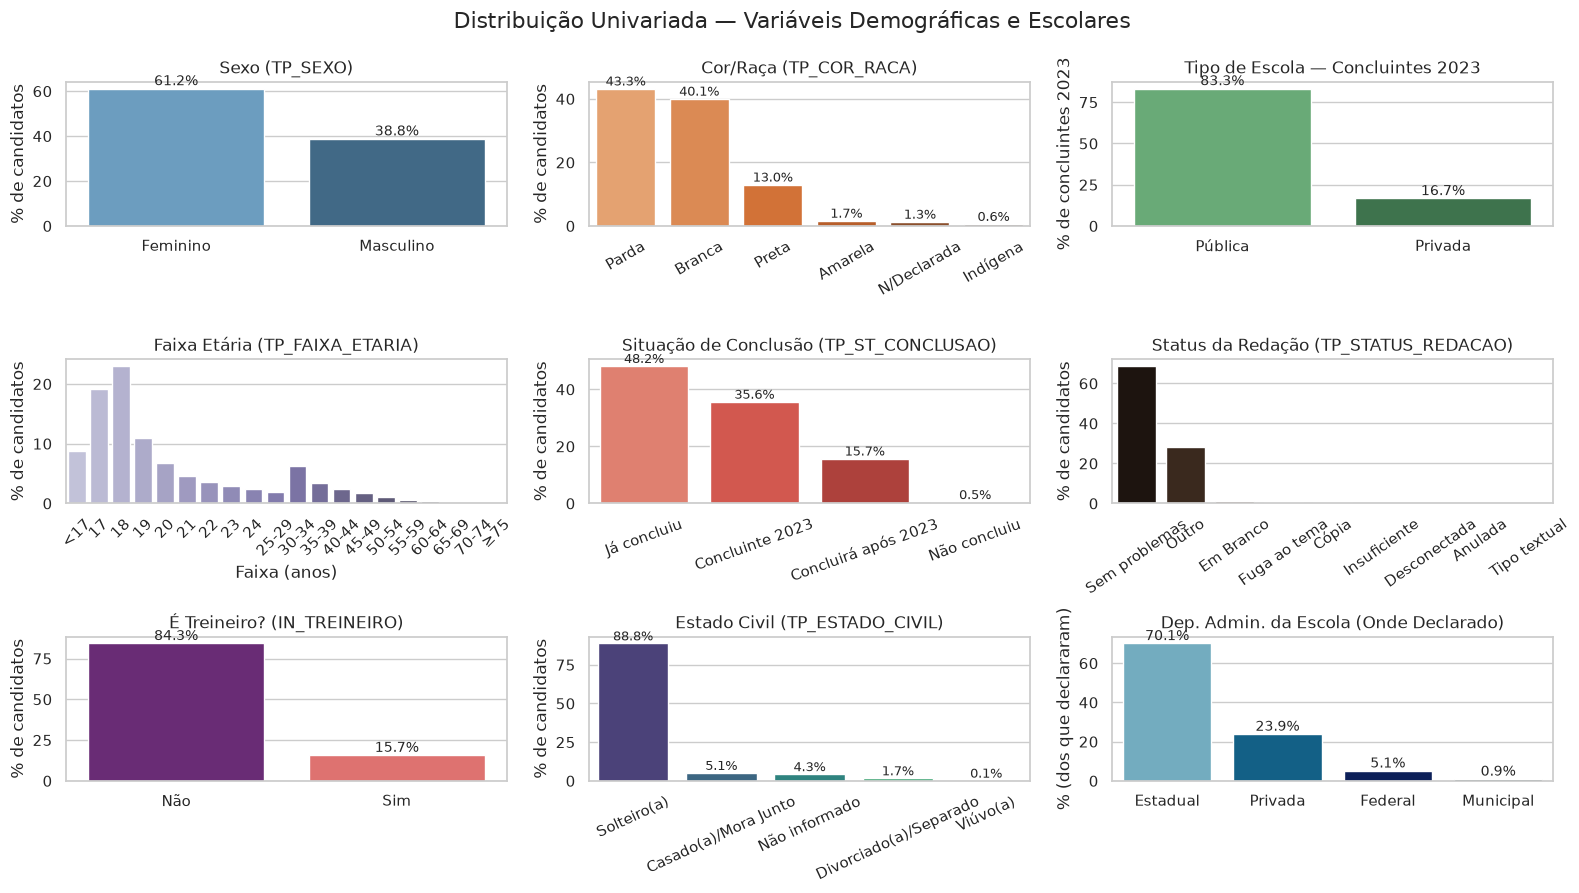

In [273]:
variaveis_demograficas_escolares()

In [274]:
# Identificar alunos presentes em todas as provas objetivas
presencas = [
    'TP_PRESENCA_CN',
    'TP_PRESENCA_CH',
    'TP_PRESENCA_LC',
    'TP_PRESENCA_MT'
]

if all(col in df.columns for col in presencas):

    # Presente = valor 1 em todas as 4 provas objetivas
    presentes_mask = (df[presencas] == 1).all(axis=1)

    # Quantidades antes da eliminação
    qtd_presentes = presentes_mask.sum()
    qtd_ausentes = len(df) - qtd_presentes
    total = len(df)

    # Mostrar situação antes da eliminação
    resultado = pd.DataFrame({
        'Situação': [
            'Presentes em todas as provas',
            'Ausentes em pelo menos uma prova'
        ],
        'Quantidade': [
            qtd_presentes,
            qtd_ausentes
        ],
        'Percentual (%)': [
            qtd_presentes / total * 100,
            qtd_ausentes / total * 100
        ]
    })

    resultado['Percentual (%)'] = resultado['Percentual (%)'].round(2)

    # Eliminar alunos ausentes em pelo menos uma prova
    df = df[presentes_mask].copy()

    print(f"Alunos restantes: {len(df):,}")
    print(f"Alunos eliminados: {qtd_ausentes:,}")

    print(f"% restantes: {qtd_presentes / total * 100:,}")
    print(f"% eliminados: {qtd_ausentes / total * 100:,}")   
     

Alunos restantes: 272,381
Alunos eliminados: 127,619
% restantes: 68.09525
% eliminados: 31.90475


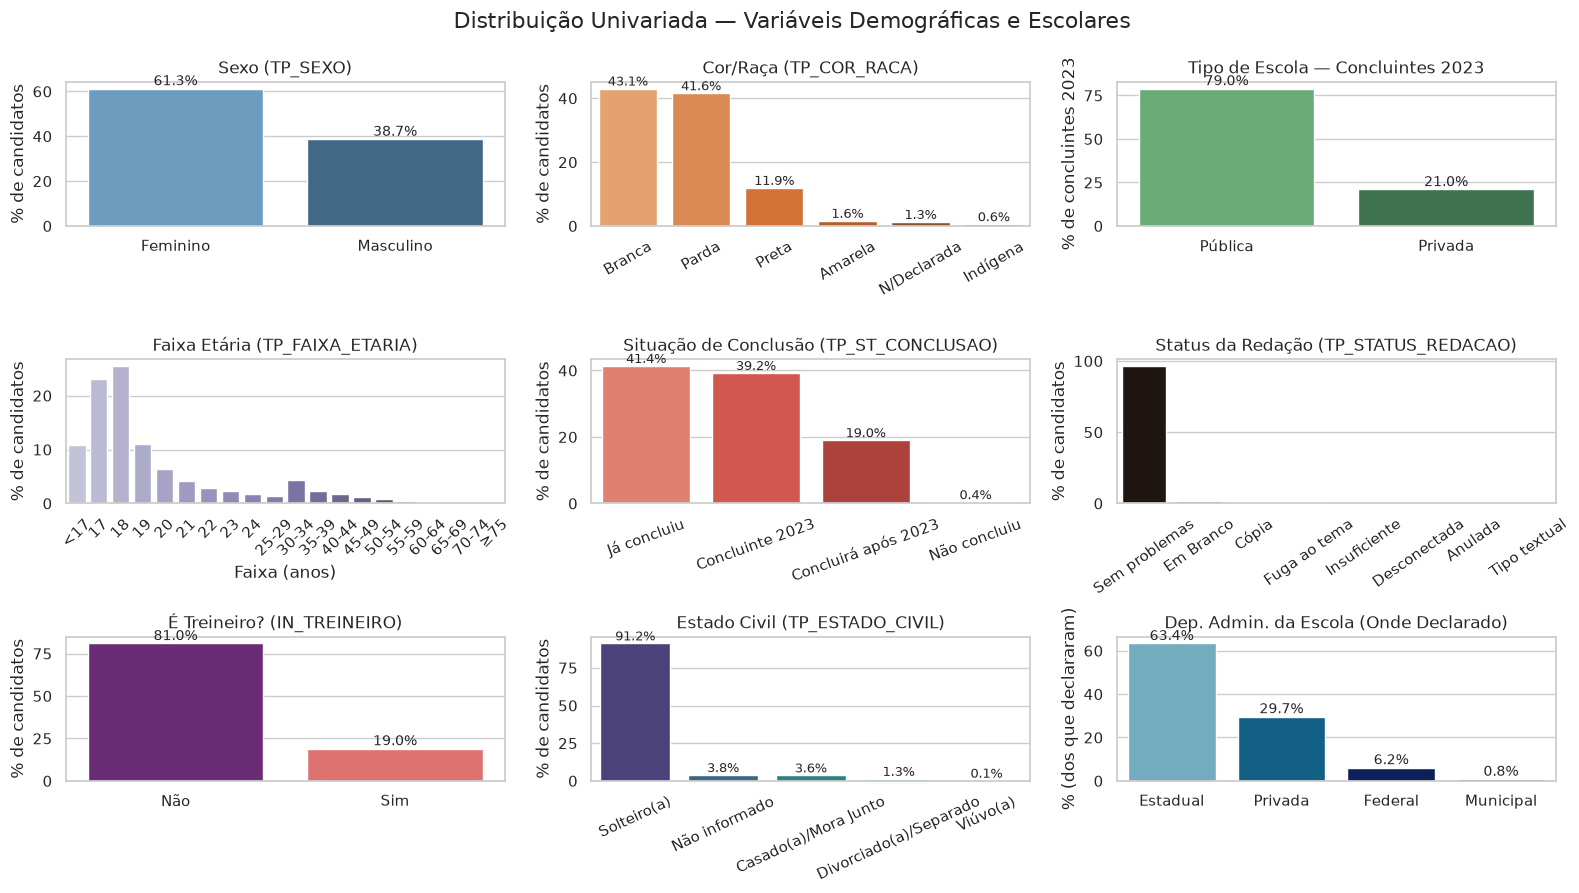

In [275]:
variaveis_demograficas_escolares()

#### 1.3 Análise dos Candidatos Treineiros e nao concluintes




O campo `IN_TREINEIRO` identifica participantes que realizaram o ENEM exclusivamente com finalidade de
treino, sem a intenção de usar a nota para acesso ao ensino superior. Esse perfil corresponde, em geral,
a estudantes do 1º e 2º anos do Ensino Médio.

Neste TCC, o objetivo é modelar o desempenho de candidatos concluintes ou que já concluiram o ensino médio.

In [276]:
# ── Filtragem do Público-Alvo (Exclusão de Treineiros e Evadidos) ────────────
print(f"Total de inscritos antes do filtro: {len(df):,}")
# Mantém apenas quem já concluiu (1) ou concluirá no ano do exame (2)
# Consequentemente, elimina quem concluirá após 2023 (3) e quem não está cursando (4)
df = df[df['TP_ST_CONCLUSAO'].isin([1, 2])].copy()
print(f"Total de inscritos após o filtro: {len(df):,}")

Total de inscritos antes do filtro: 272,381
Total de inscritos após o filtro: 219,526


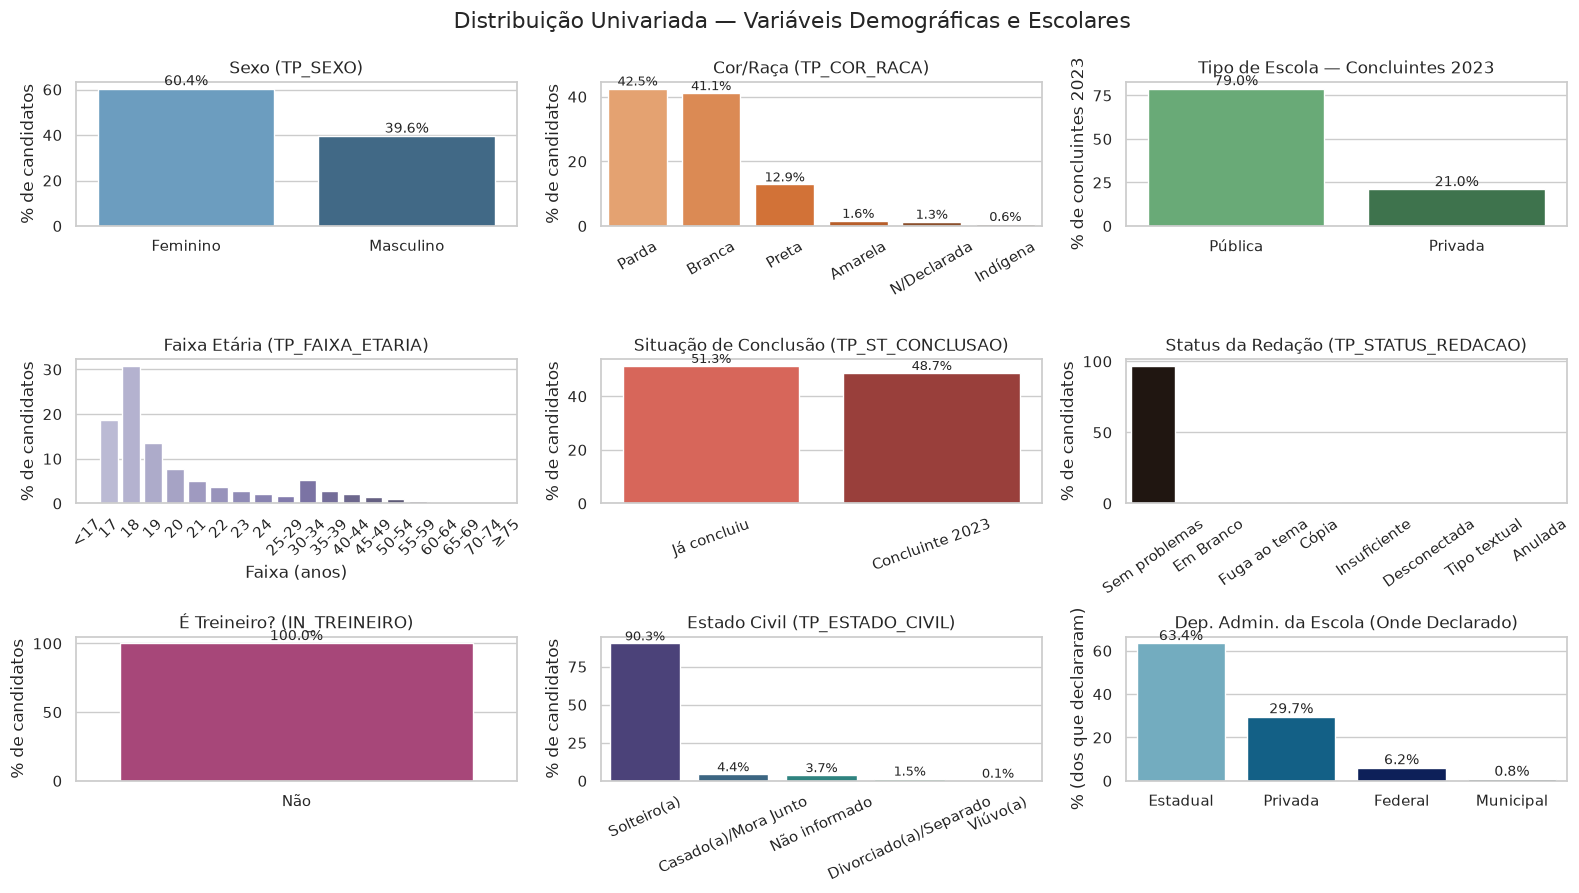

In [277]:
variaveis_demograficas_escolares()

In [278]:
import pandas as pd

# Dicionário oficial do INEP para TP_STATUS_REDACAO
labels_red = {
    1.0: '1 — Sem problemas', 
    2.0: '2 — Anulada', 
    3.0: '3 — Cópia',
    4.0: '4 — Em Branco', 
    6.0: '6 — Fuga ao tema',
    7.0: '7 — Não atendimento ao tipo textual', 
    8.0: '8 — Texto insuficiente', 
    9.0: '9 — Parte desconectada'
}

# 1. Calcula as frequências absolutas e percentuais, incluindo os Nulos (NaN)
tabela_redacao = pd.DataFrame({
    'Quantidade': df['TP_STATUS_REDACAO'].value_counts(dropna=False),
    'Percentual (%)': df['TP_STATUS_REDACAO'].value_counts(normalize=True, dropna=False) * 100
})

# 2. Traduz o índice (códigos) para os textos explicativos. 
# Se for NaN (ausente), nomeia adequadamente.
tabela_redacao.index = tabela_redacao.index.map(labels_red).fillna('NaN — Faltou / Eliminado')

# 3. Formata os números para ficarem com estilo de relatório (pontos de milhar)
tabela_redacao['Quantidade'] = tabela_redacao['Quantidade'].apply(lambda x: f"{x:,.0f}".replace(',', '.'))
tabela_redacao['Percentual (%)'] = tabela_redacao['Percentual (%)'].round(4).astype(str) + '%'

# Exibe a tabela
print("Distribuição Numérica do Status da Redação (TP_STATUS_REDACAO):\n" + "-"*65)
display(tabela_redacao)
# Elimina notas 0 em redacao
df = df[df['TP_STATUS_REDACAO'] == 1].copy()



Distribuição Numérica do Status da Redação (TP_STATUS_REDACAO):
-----------------------------------------------------------------


,Quantidade,Percentual (%)
TP_STATUS_REDACAO,,
1 — Sem problemas,212.387,96.748%
4 — Em Branco,2.665,1.214%
6 — Fuga ao tema,1.774,0.8081%
3 — Cópia,1.665,0.7585%
8 — Texto insuficiente,570,0.2597%
9 — Parte desconectada,167,0.0761%
7 — Não atendimento ao tipo textual,155,0.0706%
2 — Anulada,143,0.0651%


**conclusao**
1. O Problema da Distribuição do Target (Zero-Inflated)
O seu objetivo é prever a nota das provas (um problema clássico de Regressão). Por regra do ENEM, qualquer aluno que caia nos status 2, 3, 4, 6, 7, 8 ou 9 recebe automaticamente a nota zero na redação. Se você mantiver esses alunos na base, a variável alvo (Target) deixará de ser uma curva contínua (estilo "sino") e passará a ter um pico gigantesco e artificial no valor 0. Modelos de regressão (como Random Forest, XGBoost ou Regressão Linear) sofrem horrores com dados "Zero-Inflated" (inflados de zero). O algoritmo vai tentar puxar as previsões de todo mundo para baixo para tentar compensar esses zeros, piorando seu Erro Médio Absoluto (MAE) e o RMSE.

2. Ruído Causal vs. Variáveis Preditivas
Pense nas features (variáveis) que você vai dar ao modelo: renda familiar, escolaridade da mãe, tipo de escola, etc. Essas variáveis são ótimas para tentar deduzir a capacidade acadêmica do aluno (se ele tira 500, 700 ou 900). No entanto, um aluno de escola de elite, com alta renda familiar, pode muito bem receber nota zero porque entrou em pânico e entregou a prova "Em Branco", ou porque se distraiu e cometeu "Fuga ao tema".

Esses são eventos comportamentais/anômalos e você não tem variáveis no dataset do INEP para prever o psicológico ou a distração do aluno no dia. Inserir essas pessoas no treinamento fará com que o modelo "se confunda" (ruído), pois ele verá pessoas com atributos socioeconômicos idênticos tendo notas finais totalmente discrepantes (uma tira 900 e a outra tira 0).

3. Apenas 3,2% de Perda de Dados
Em Data Science, choramos muito quando precisamos jogar dados fora. Mas repare na sua tabela: manter o grupo "1" significa que você reterá 96,7% da sua base de dados atual. Jogar fora 3,2% de dados anômalos que destruiriam a curva do seu regressor é um preço minúsculo (e extremamente barato) a se pagar.

**"Para o treinamento do modelo preditivo de regressão, optou-se por excluir os registros onde TP_STATUS_REDACAO era diferente de '1' (Sem problemas), o que representou o descarte de aproximadamente 3,2% da amostra. Esta decisão metodológica baseou-se no fato de que status anômalos (como Fuga ao Tema, Anulada ou Cópia) resultam em notas zero forçadas por regras de correção, introduzindo ruídos no algoritmo (efeito zero-inflated) que não são explicáveis pelas covariáveis socioeconômicas e demográficas utilizadas no estudo."**

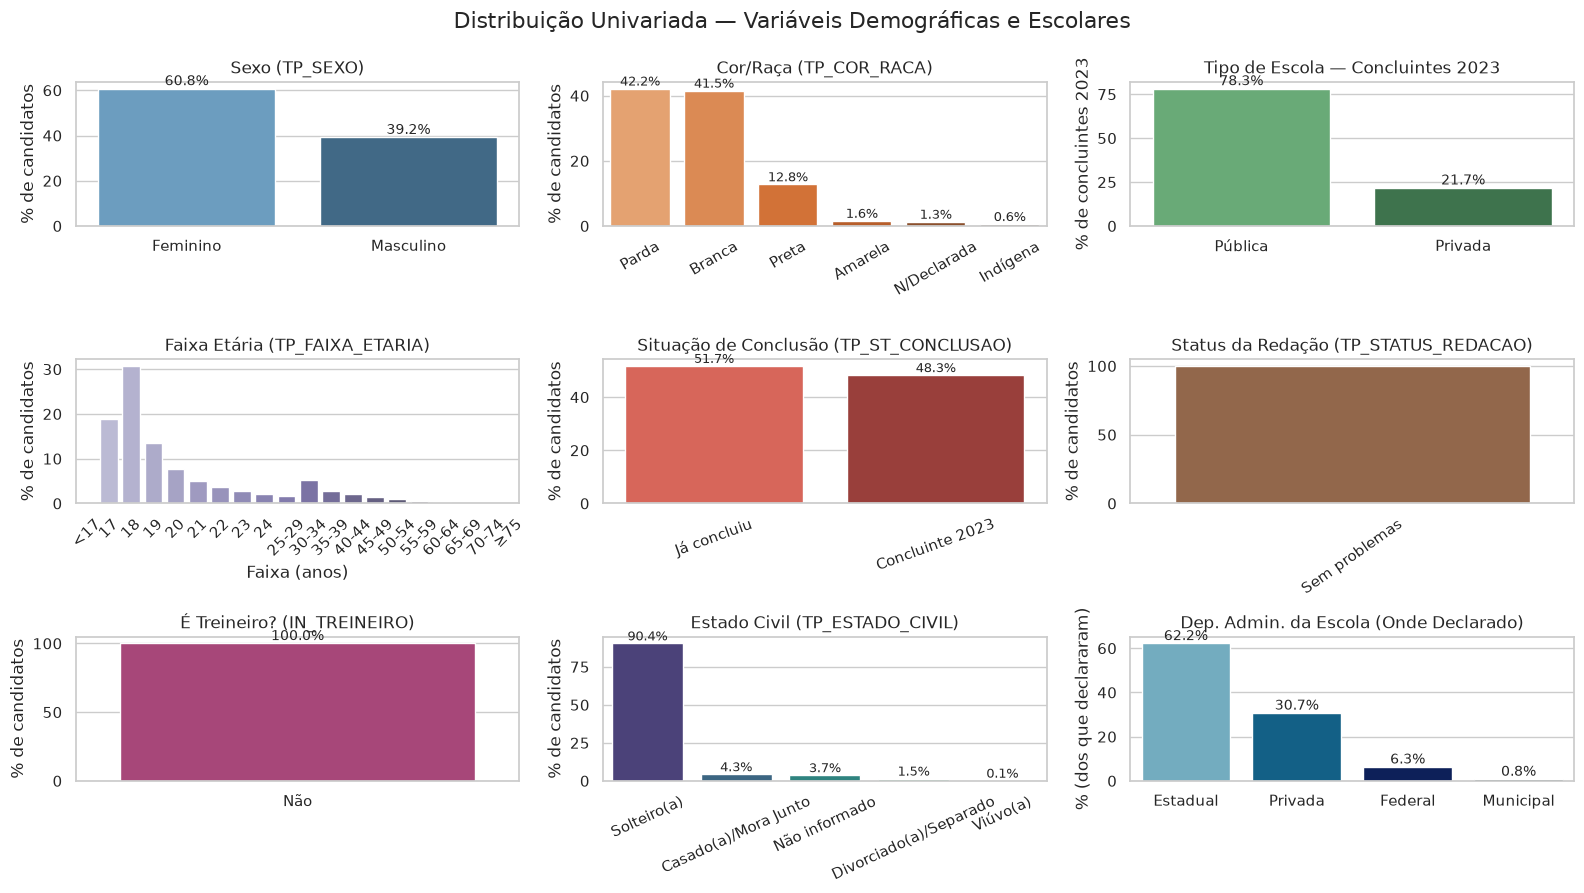

In [279]:
variaveis_demograficas_escolares()

Eliminação das features 'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', uma vez que eu ja eliminei os registros de alunos que faltaram. 

In [280]:
# Essas colunas têm variância zero após o filtro de presença
# (todos os registros restantes têm valor 1)
cols_presenca = ['TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT']

# Validação antes de remover (boa prática)
assert (df[cols_presenca] == 1).all().all(), "Atenção: há registros com presença != 1!"

df = df.drop(columns=cols_presenca)


O objetivo do modelo preditivo é estimar o desempenho de um candidato **antes** da realização da prova, com base em suas características demográficas, socioeconômicas e escolares coletadas no momento da inscrição.

Nesse cenário, as variáveis `CO_PROVA_CN`, `CO_PROVA_CH`, `CO_PROVA_LC` e `CO_PROVA_MT` **não estariam disponíveis no momento da predição**: o caderno de prova é sorteado e atribuído ao candidato apenas no dia do exame, portanto *após* a data de inscrição.

Adicionalmente, o ENEM utiliza a **Teoria de Resposta ao Item (TRI)** para o cálculo das notas — metodologia que calibra cada questão individualmente e normaliza o desempenho entre cadernos distintos (azul, amarelo, cinza, etc.). Portanto, o código do caderno não carrega informação de dificuldade relativa que justificaria sua inclusão como variável preditora.

Por essas duas razões — **indisponibilidade temporal** e **ausência de poder preditivo intrínseco após a TRI** —, essas variáveis são removidas da base de dados nesta etapa.

> **Nota:** variáveis de caderno para necessidades especiais (Braille, Libras etc.) poderiam,
> em tese, ser convertidas em flag binário de acessibilidade. Entretanto, o dataset já contém
> variáveis `IN_*` que capturam essas condições diretamente, tornando o código do caderno redundante.

In [281]:
# Remoção das variáveis de código do caderno de prova
#
# Justificativa:
#   1. Indisponibilidade temporal: o caderno é atribuído no dia da prova,
#      após a inscrição do candidato — portanto não estaria disponível
#      em um cenário real de predição pré-prova.
#   2. Ausência de poder preditivo: a TRI já normaliza a dificuldade entre
#      cadernos distintos ao calcular as notas finais.

cols_caderno = ['CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT']

# Verificação defensiva: remove apenas as colunas que existem no DataFrame
cols_para_remover = [c for c in cols_caderno if c in df.columns]

df = df.drop(columns=cols_para_remover)

print(f'Colunas removidas : {cols_para_remover}')
print(f'Shape resultante  : {df.shape[0]:,} linhas x {df.shape[1]} colunas')

Colunas removidas : ['CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT']
Shape resultante  : 212,387 linhas x 69 colunas


#### 1.4 Levantamento inicial de valores ausentes

Esta etapa identifica as variáveis que apresentam valores ausentes. A presença de `NaN` não será tratada automaticamente como erro: padrões de ausência serão investigados antes de qualquer decisão de exclusão ou imputação.

In [282]:
print(f"Base carregada! Linhas: {df.shape[0]}, Colunas: {df.shape[1]}\n")

pd.set_option('display.max_rows', None)

info = pd.DataFrame({
    'Índice': range(len(df.columns)),
    'Tipo': df.dtypes.astype(str),
    'Não nulos': df.notna().sum().values,
    'Nulos': df.isna().sum().values,
    '% Nulos': (df.isna().sum().values / len(df) * 100).round(2)
})

print(info[info['Nulos'] != 0])

Base carregada! Linhas: 212387, Colunas: 69

                        Índice     Tipo  Não nulos   Nulos  % Nulos
TP_ENSINO                   10  float64     100499  111888    52.68
CO_MUNICIPIO_ESC            12  float64      70536  141851    66.79
NO_MUNICIPIO_ESC            13      str      70536  141851    66.79
CO_UF_ESC                   14  float64      70536  141851    66.79
SG_UF_ESC                   15      str      70536  141851    66.79
TP_DEPENDENCIA_ADM_ESC      16  float64      70536  141851    66.79
TP_LOCALIZACAO_ESC          17  float64      70536  141851    66.79
TP_SIT_FUNC_ESC             18  float64      70536  141851    66.79


#### 1.5 Investigação do padrão de ausência das variáveis escolares



As variáveis abaixo apresentam o mesmo percentual de ausência. Antes de decidir qualquer tratamento, vamos verificar se elas também compartilham o mesmo padrão de presença/ausência e como esse padrão se relaciona com `TP_ST_CONCLUSAO`.

Os nulos ocorrem nas mesmas linhas para as 7 variáveis? SIM



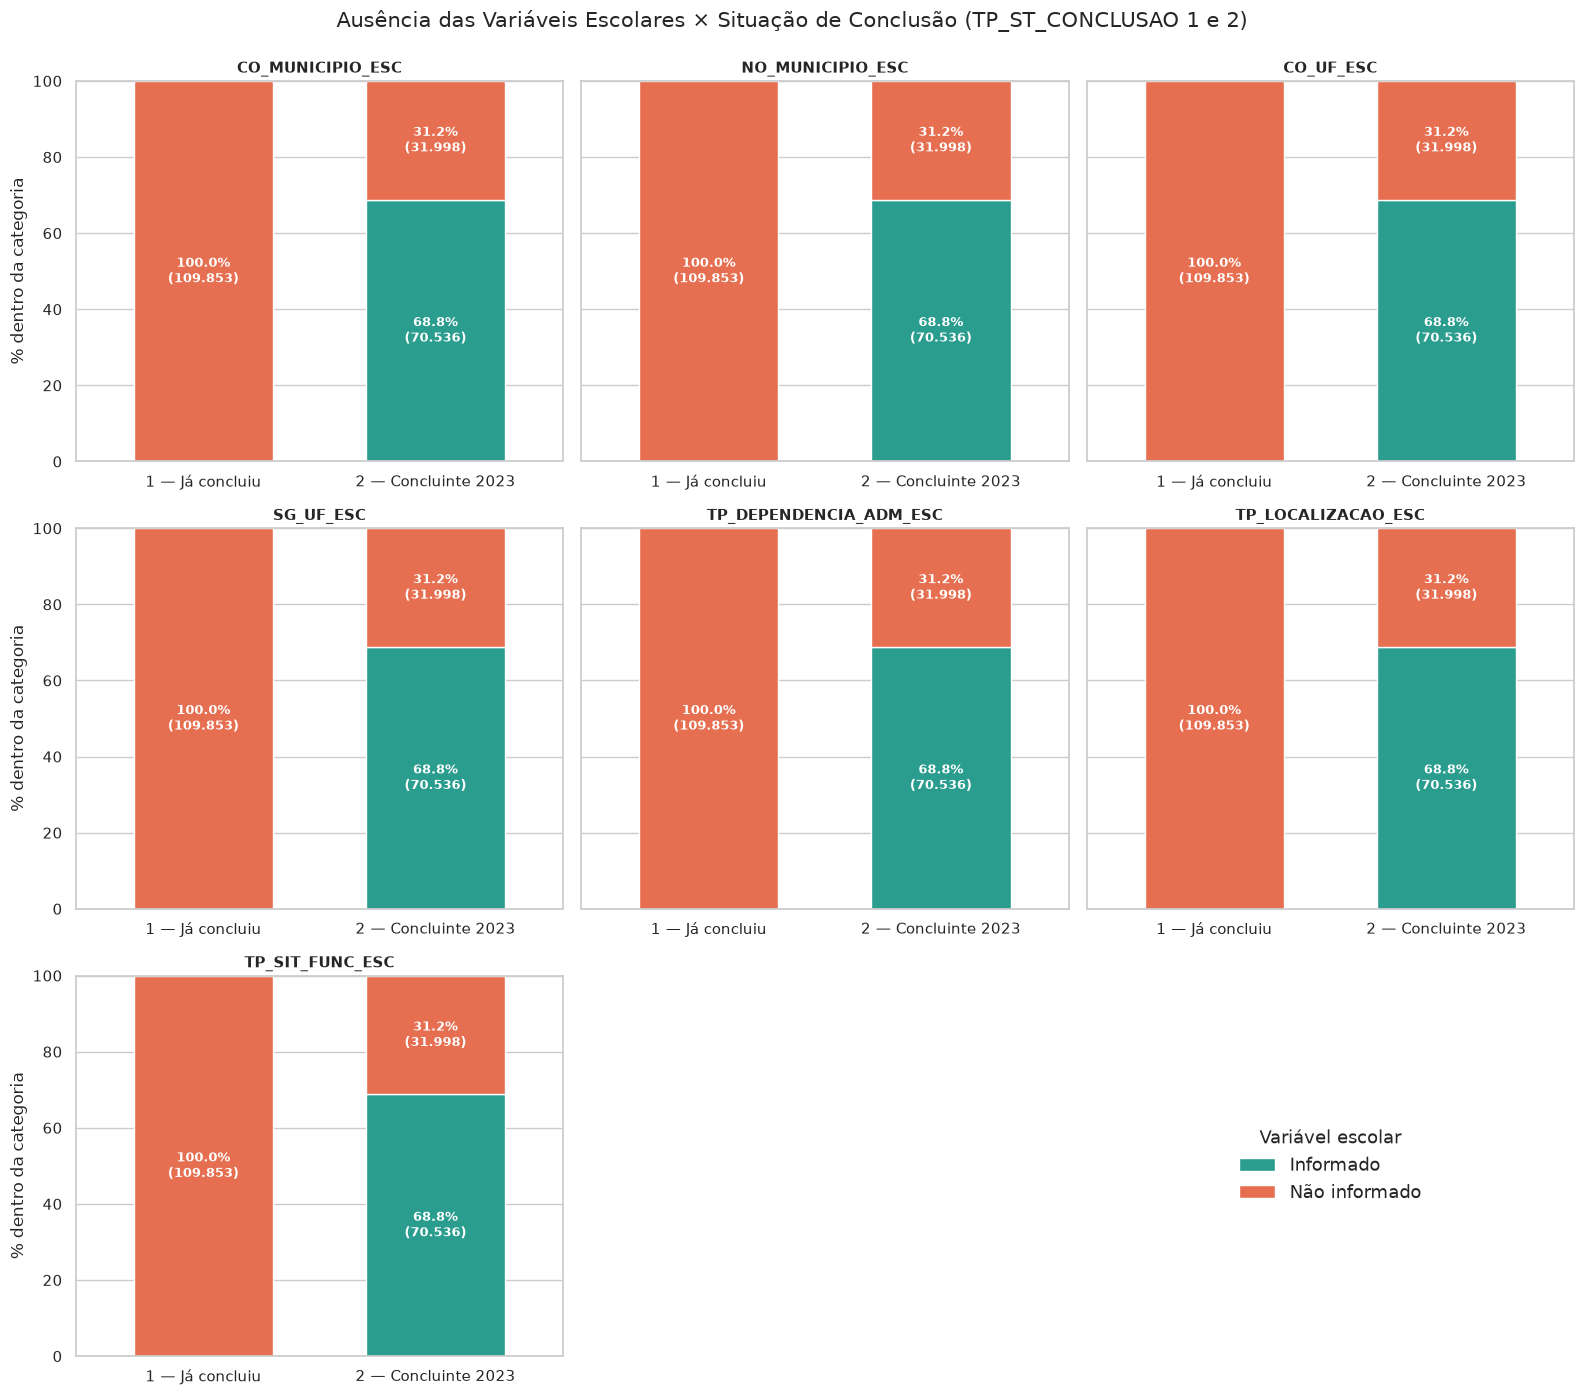

In [283]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

# ── Variáveis com 66,79% de nulos (informações da escola) ────────────────────
VARS_ESC = [
    'CO_MUNICIPIO_ESC', 'NO_MUNICIPIO_ESC', 'CO_UF_ESC', 'SG_UF_ESC',
    'TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC', 'TP_SIT_FUNC_ESC'
]

LABELS_CONC_12 = {1: '1 — Já concluiu', 2: '2 — Concluinte 2023'}
CORES = {'Informado': '#2a9d8f', 'Não informado': '#e76f51'}

# Mantém apenas os códigos 1 e 2 de TP_ST_CONCLUSAO
df_plot = df[df['TP_ST_CONCLUSAO'].isin([1, 2])]

# ── Checagem: os nulos estão nas MESMAS linhas para as 7 variáveis? ──────────
mascara_nulos = df_plot[VARS_ESC].isna()
mesmo_padrao = mascara_nulos.nunique(axis=1).eq(1).all()
print(f"Os nulos ocorrem nas mesmas linhas para as 7 variáveis? {'SIM' if mesmo_padrao else 'NÃO'}\n")

# ── Painel de gráficos ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 3, figsize=(16, 14), sharey=True)
fig.suptitle("Ausência das Variáveis Escolares × Situação de Conclusão (TP_ST_CONCLUSAO 1 e 2)",
             fontsize=15, y=0.995)
axes = axes.flatten()

for ax, var in zip(axes, VARS_ESC):
    # Frequência absoluta: linhas = conclusão (1, 2) | colunas = nulo (False/True)
    ct_abs = pd.crosstab(df_plot['TP_ST_CONCLUSAO'], df_plot[var].isna())
    ct_abs = ct_abs.reindex(index=[1, 2], columns=[False, True], fill_value=0)
    ct_abs.columns = ['Informado', 'Não informado']
    ct_abs.index = ct_abs.index.map(LABELS_CONC_12)

    # Frequência relativa (% dentro de cada categoria de conclusão)
    ct_pct = ct_abs.div(ct_abs.sum(axis=1), axis=0) * 100

    ct_pct.plot(kind='bar', stacked=True, ax=ax, width=0.6, edgecolor='white',
                color=[CORES[c] for c in ct_pct.columns], legend=False)

    # Rótulos: percentual + quantidade absoluta
    for container, col in zip(ax.containers, ct_pct.columns):
        labels = [
            f"{p:.1f}%\n({n:,})".replace(',', '.') if p > 3 else ''
            for p, n in zip(ct_pct[col], ct_abs[col])
        ]
        ax.bar_label(container, labels=labels, label_type='center',
                     fontsize=9, color='white', fontweight='bold')

    ax.set_title(var, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 100)
    ax.set_xlabel('')
    ax.set_ylabel('% dentro da categoria')
    ax.tick_params(axis='x', rotation=0)

# Desliga os eixos sem gráfico e coloca a legenda num deles
for ax in axes[len(VARS_ESC):]:
    ax.axis('off')

legenda = [Patch(facecolor=cor, label=lbl) for lbl, cor in CORES.items()]
axes[-1].legend(handles=legenda, loc='center', fontsize=13,
                title='Variável escolar', title_fontsize=13, frameon=False)

plt.tight_layout()
plt.show()


Análise da variável `TP_ENSINO`

A distribuição de `TP_ENSINO` será analisada inicialmente sem qualquer decisão de exclusão ou imputação. O dicionário de dados apresenta dois códigos válidos para esta variável: `1` — Ensino Regular e `2` — Educação Especial - Modalidade Substitutiva.

A presença de valores ausentes será investigada antes de qualquer tratamento.

ANÁLISE DE AUSÊNCIA ESTRUTURAL (MNAR) - Variável: TP_ENSINO

Proporção de valores ausentes por Grupo (%):


status_preenchimento,TP_ENSINO informado,TP_ENSINO não informado
Situacao_Conclusao,,
Concluintes (estudam e concluem em 2023),98.02,1.98
Já concluíram,0.00,100.00


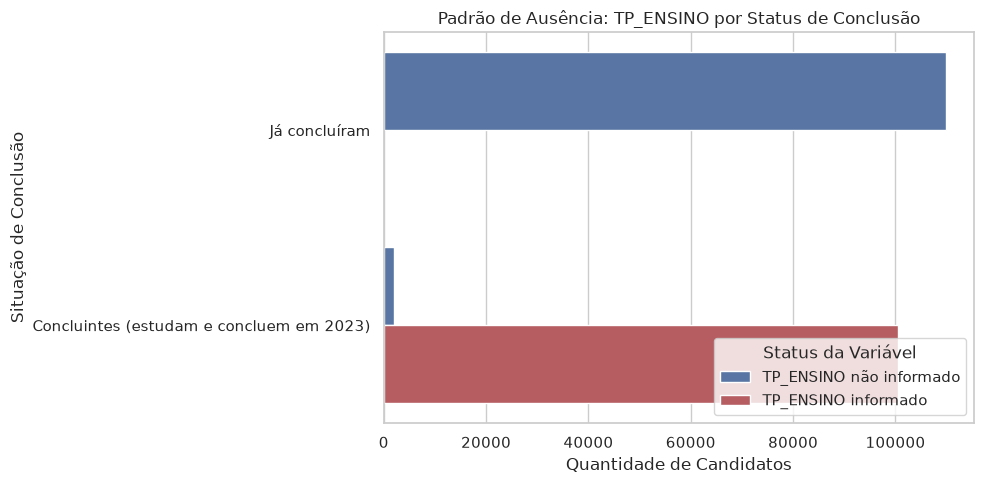

In [284]:
analisa_mnar(df, 'TP_ENSINO', 'TP_ENSINO informado', 'TP_ENSINO não informado')

#### 1.6 Tratamento de Valores Ausentes: Imputação Lógica e Categórica para Concluintes

Durante a análise do padrão de ausência (Missing Not At Random - MNAR), identificou-se que alunos egressos (`TP_ST_CONCLUSAO == 1`) possuem 100% de ausência nas variáveis escolares por uma questão estrutural do questionário. Optou-se por separar a modelagem destes dois grupos.

Para o grupo de **Concluintes em 2023** (`TP_ST_CONCLUSAO == 2`), ainda assim observou-se 31,2% de valores ausentes (NaN) nas variáveis escolares. Como a exclusão dessas colunas causaria perda de forte poder preditivo (ex: Tipo de Escola) e a exclusão das linhas comprometeria o tamanho da amostra, foram adotadas duas estratégias de imputação:

1. **Imputação Lógica (Proxy espacial):** Para as variáveis de localização da escola (`CO_UF_ESC`, `SG_UF_ESC`, `CO_MUNICIPIO_ESC`, `NO_MUNICIPIO_ESC`), foi assumida a premissa de que o aluno concluinte estuda na mesma cidade/estado em que realiza a prova. Os valores nulos da escola foram preenchidos com os respectivos dados do local de prova.
2. **Imputação Categórica (Missing como feature):** Para as variáveis administrativas (`TP_DEPENDENCIA_ADM_ESC`, `TP_LOCALIZACAO_ESC`, `TP_SIT_FUNC_ESC`, `TP_ENSINO`), a imputação pela moda inseriria um viés estatístico indesejado. Como será utilziado um modelo baseado em árvore de decisão (*Random Forest*), serão substituidos os valores `NaN` pela categoria `0` (representando "Não Informado"). Modelos de árvore são eficientes em isolar categorias de ausência, podendo extrair padrão preditivo do próprio fato de o candidato não ter prestado a informação.

In [285]:
# Cria uma máscara para filtrar apenas os alunos concluintes em 2023
# (TP_ST_CONCLUSAO == 2 significa "Estou cursando e concluirei o Ensino Médio no ano letivo...")
mask_concluintes = (df['TP_ST_CONCLUSAO'] == 2)

# ==========================================
# 1. IMPUTAÇÃO LÓGICA (Localização da Escola)
# Substitui NaN da Escola pelos dados do Local de Prova
# ==========================================
mapeamento_localizacao = {
    'CO_MUNICIPIO_ESC': 'CO_MUNICIPIO_PROVA',
    'NO_MUNICIPIO_ESC': 'NO_MUNICIPIO_PROVA',
    'CO_UF_ESC': 'CO_UF_PROVA',
    'SG_UF_ESC': 'SG_UF_PROVA'
}

for col_escola, col_prova in mapeamento_localizacao.items():
    # Preenche os NaNs da coluna da escola usando os valores da coluna de prova, apenas para os concluintes
    df.loc[mask_concluintes, col_escola] = df.loc[mask_concluintes, col_escola].fillna(df.loc[mask_concluintes, col_prova])

# ==========================================
# 2. IMPUTAÇÃO CATEGÓRICA (Dados Administrativos)
# Substitui NaN por 0 (Categoria: "Não Informado")
# ==========================================
colunas_administrativas = [
    'TP_ENSINO', 
    'TP_DEPENDENCIA_ADM_ESC', 
    'TP_LOCALIZACAO_ESC', 
    'TP_SIT_FUNC_ESC'
]

for col in colunas_administrativas:
    # Preenche com 0 (representando "Não Informado") apenas para os concluintes
    df.loc[mask_concluintes, col] = df.loc[mask_concluintes, col].fillna(0)

# Verificação do resultado para o grupo de concluintes:
print("Valores nulos restantes nas variáveis escolares (apenas concluintes):")
print(df.loc[mask_concluintes, list(mapeamento_localizacao.keys()) + colunas_administrativas].isnull().sum())


Valores nulos restantes nas variáveis escolares (apenas concluintes):
CO_MUNICIPIO_ESC          0
NO_MUNICIPIO_ESC          0
CO_UF_ESC                 0
SG_UF_ESC                 0
TP_ENSINO                 0
TP_DEPENDENCIA_ADM_ESC    0
TP_LOCALIZACAO_ESC        0
TP_SIT_FUNC_ESC           0
dtype: int64


**O que essa função faz:**

**Mapeamento:** 
Ela traduz os códigos 1, 2, 3 e 4 da coluna TP_ST_CONCLUSAO para texto legível, facilitando a interpretação do gráfico.

**Tabela Cruzada (pd.crosstab):** 
Ela calcula matematicamente a exata porcentagem de ausência para cada grupo (reproduzindo aquele insight exato de 100% e 31.2% que você citou).

**Plotagem:** 
Usa o seaborn para recriar o gráfico de barras comparando os grupos visualmente.

ANÁLISE DE AUSÊNCIA ESTRUTURAL (MNAR) - Variável: TP_ENSINO

Proporção de valores ausentes por Grupo (%):


status_preenchimento,TP_ENSINO informado,TP_ENSINO não informado
Situacao_Conclusao,,
Concluintes (estudam e concluem em 2023),100.0,0.0
Já concluíram,0.0,100.0


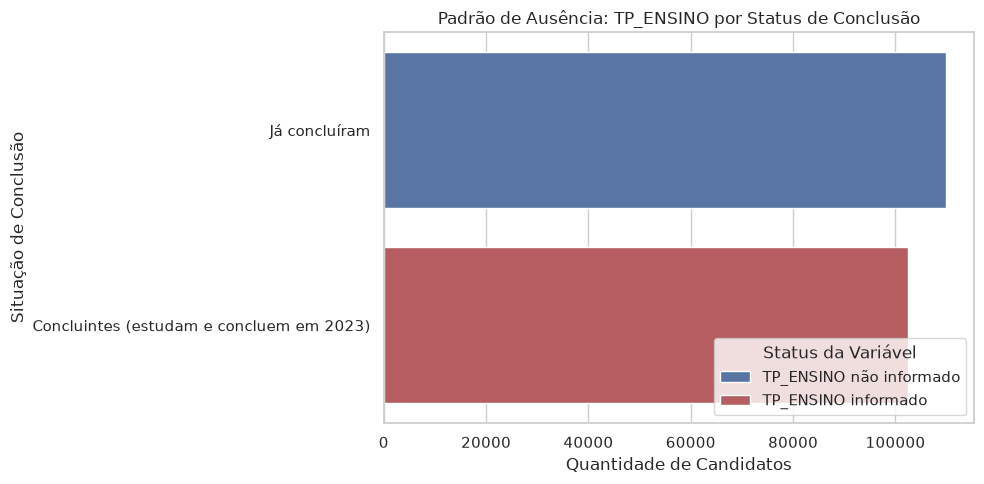

In [286]:
analisa_mnar(df, 'TP_ENSINO', 'TP_ENSINO informado', 'TP_ENSINO não informado')

**Observação da EDA:** o cruzamento mostra um padrão claro de ausência. Nos grupos `1 — Já concluiu`, `3 — Concluirá após 2023` e `4 — Não concluiu/não cursa`, `TP_ENSINO` está 100% não informado. No grupo `2 — Concluinte em 2023`, 97,99% dos registros possuem `TP_ENSINO` informado e 2,01% não possuem.

Esse resultado indica que a ausência de `TP_ENSINO` está fortemente associada à situação de conclusão do Ensino Médio. Portanto, os valores ausentes não devem ser tratados, neste momento, como ausência aleatória de informação. A decisão sobre manter, excluir ou tratar essa variável será tomada posteriormente, após a análise das demais características e a definição do problema preditivo.

#### 1.7 Análise da variável `NU_INSCRICAO`

Resultado da análise de unicidade: não foram identificadas inscrições duplicadas na amostra analisada do ENEM 2023. NU_INSCRICAO apresenta unicidade de 100% nesta base. A variável é uma máscara de inscrição e não deve ser interpretada como identificador pessoal ou como mecanismo para identificar o mesmo participante em diferentes edições do ENEM.

In [287]:
# Verificação de registros completamente duplicados

duplicados = df.duplicated().sum()

print(f"Quantidade de registros duplicados: {duplicados:,}")
print(
    f"Percentual de registros duplicados: "
    f"{duplicados / len(df) * 100:.2f}%"
)

Quantidade de registros duplicados: 0
Percentual de registros duplicados: 0.00%


#### 1.8 Análise de outliers


 O conjunto de dados do ENEM contém diversas variáveis numéricas que representam códigos de categorias, como sexo, estado civil, cor/raça e situação de conclusão do ensino médio. Para essas variáveis, a identificação de outliers por métodos estatísticos como o intervalo interquartil (IQR) não possui interpretação adequada.

Assim, nesta etapa, o primeiro objetivo será reunir em uma lista, as variáveis que possuem características quantitativas e, posteriormente, investigar a presença de valores extremos nessas variáveis.

A investigação de outliers não implica, neste momento, a exclusão de nenhum registro. O objetivo é compreender o comportamento dos dados e verificar se existem valores que mereçam uma análise mais detalhada.

In [288]:
# Variáveis quantitativas selecionadas para investigação de outliers

variaveis_quantitativas = [
    'NU_NOTA_CN',      # Nota da prova de Ciências da Natureza
    'NU_NOTA_CH',      # Nota da prova de Ciências Humanas
    'NU_NOTA_LC',      # Nota da prova de Linguagens e Códigos
    'NU_NOTA_MT',      # Nota da prova de Matemática
    'NU_NOTA_COMP1',   # Nota da competência 1 - Demonstrar domínio da modalidade escrita...
    'NU_NOTA_COMP2',   # Nota da competência 2 - Compreender a proposta de redação e aplicar...
    'NU_NOTA_COMP3',   # Nota da competência 3 - Selecionar, relacionar, organizar e interpretar...
    'NU_NOTA_COMP4',   # Nota da competência 4 - Demonstrar conhecimento dos mecanismos...
    'NU_NOTA_COMP5',   # Nota da competência 5 - Elaborar proposta de intervenção...
    'NU_NOTA_REDACAO'  # Nota da prova de redação 
]

Serão analisadas medidas de tendência central e de dispersão, incluindo quantidade de observações, média, desvio-padrão, valores mínimo e máximo e quartis.

A presença de um valor distante da média, por si só, não caracteriza um erro ou justifica sua exclusão. Valores extremos podem representar observações legítimas da população.

In [289]:
# Estatísticas descritivas das variáveis quantitativas

estatisticas = df[variaveis_quantitativas].describe().T

estatisticas = estatisticas[
    ['mean', 'std', 'min', '25%', '50%', '75%', 'max']
]

estatisticas.columns = [
    'Média',
    'DsvPdr',
    'Mínimo',
    '1º Q',
    'Mediana',
    '3º Q',
    'Máximo'
]

estatisticas = estatisticas.round(2)

print("Estatísticas descritivas das variáveis quantitativas:")
print(estatisticas)

Estatísticas descritivas das variáveis quantitativas:
                  Média  DsvPdr  Mínimo   1º Q  Mediana   3º Q  Máximo
NU_NOTA_CN       499.50   86.81     0.0  443.1    496.4  553.8   868.4
NU_NOTA_CH       529.87   86.72     0.0  474.9    535.8  590.4   823.0
NU_NOTA_LC       523.15   73.56     0.0  476.3    526.9  574.0   820.8
NU_NOTA_MT       535.87  130.97     0.0  432.5    524.2  631.2   958.6
NU_NOTA_COMP1    126.95   25.83     0.0  120.0    120.0  140.0   200.0
NU_NOTA_COMP2    145.48   43.73    40.0  120.0    140.0  180.0   200.0
NU_NOTA_COMP3    124.14   36.88     0.0  100.0    120.0  140.0   200.0
NU_NOTA_COMP4    135.86   35.60     0.0  120.0    120.0  160.0   200.0
NU_NOTA_COMP5    114.39   58.61     0.0   80.0    120.0  160.0   200.0
NU_NOTA_REDACAO  646.82  177.27    40.0  520.0    620.0  800.0  1000.0


**Conclusao**

Pode se observar que nas notas de CN, CH, LC e REDACAO, a média e mediana divergem pouco, já em MT, essa diferença  é mais acentuada e esse resultado pode ser observado também pelo desvio padrao de MT que é maior que o de CN, CH e LC, indicando aqui uma assimetria à direita. No entanto, observa-se também que o desvio padrão de REDACAO é ainda maior que o de MT, porém a media e mediana encontram-se próximas, o que denota uma maior distribuicao das notas de redacao e que podem ser explicadas pela composicao das notas de redacao (NU_NOTA_COMP1 a NU_NOTA_COMP5), que é calculada pela média aritmetica. Cabe lembrar que essas competencias sao corrigidas por dois professores que atribuem notas de 0 a 200 em valores multiplos de 40 pontos.

Aqui eu faço uma varredura por candidatos que aparentemente fizeram apenas a redação.

In [290]:
colunas_notas = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT']
colunas_redacao = ['NU_NOTA_COMP1', 'NU_NOTA_COMP2', 'NU_NOTA_COMP3',
                   'NU_NOTA_COMP4', 'NU_NOTA_COMP5', 'NU_NOTA_REDACAO']

todas_zero = (df[colunas_notas] == 0).all(axis=1)

print(f"Linhas com TODAS as notas objetivas iguais a zero: {todas_zero.sum()}")
print(f"Proporção da base: {todas_zero.mean():.6%} (de {len(df)} linhas)\n")

# Notas completas (objetivas + redação) do(s) registro(s) encontrado(s)
registro = df.loc[todas_zero, colunas_notas + colunas_redacao]
print(registro.to_string())

# Registro de auditoria: guarda o que foi removido, para documentar no TCC
removidos = df.loc[todas_zero].copy()

n_antes = len(df)
df = df.loc[~todas_zero].reset_index(drop=True)

print(f"Linhas antes:     {n_antes}")
print(f"Linhas removidas: {len(removidos)}")
print(f"Linhas depois:    {len(df)}")


Linhas com TODAS as notas objetivas iguais a zero: 1
Proporção da base: 0.000471% (de 212387 linhas)

        NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  NU_NOTA_COMP1  NU_NOTA_COMP2  NU_NOTA_COMP3  NU_NOTA_COMP4  NU_NOTA_COMP5  NU_NOTA_REDACAO
119177         0.0         0.0         0.0         0.0          160.0          160.0          160.0          160.0          160.0            800.0
Linhas antes:     212387
Linhas removidas: 1
Linhas depois:    212386


**Conclusao**
Esse candidato foi eliminado da base de dados.

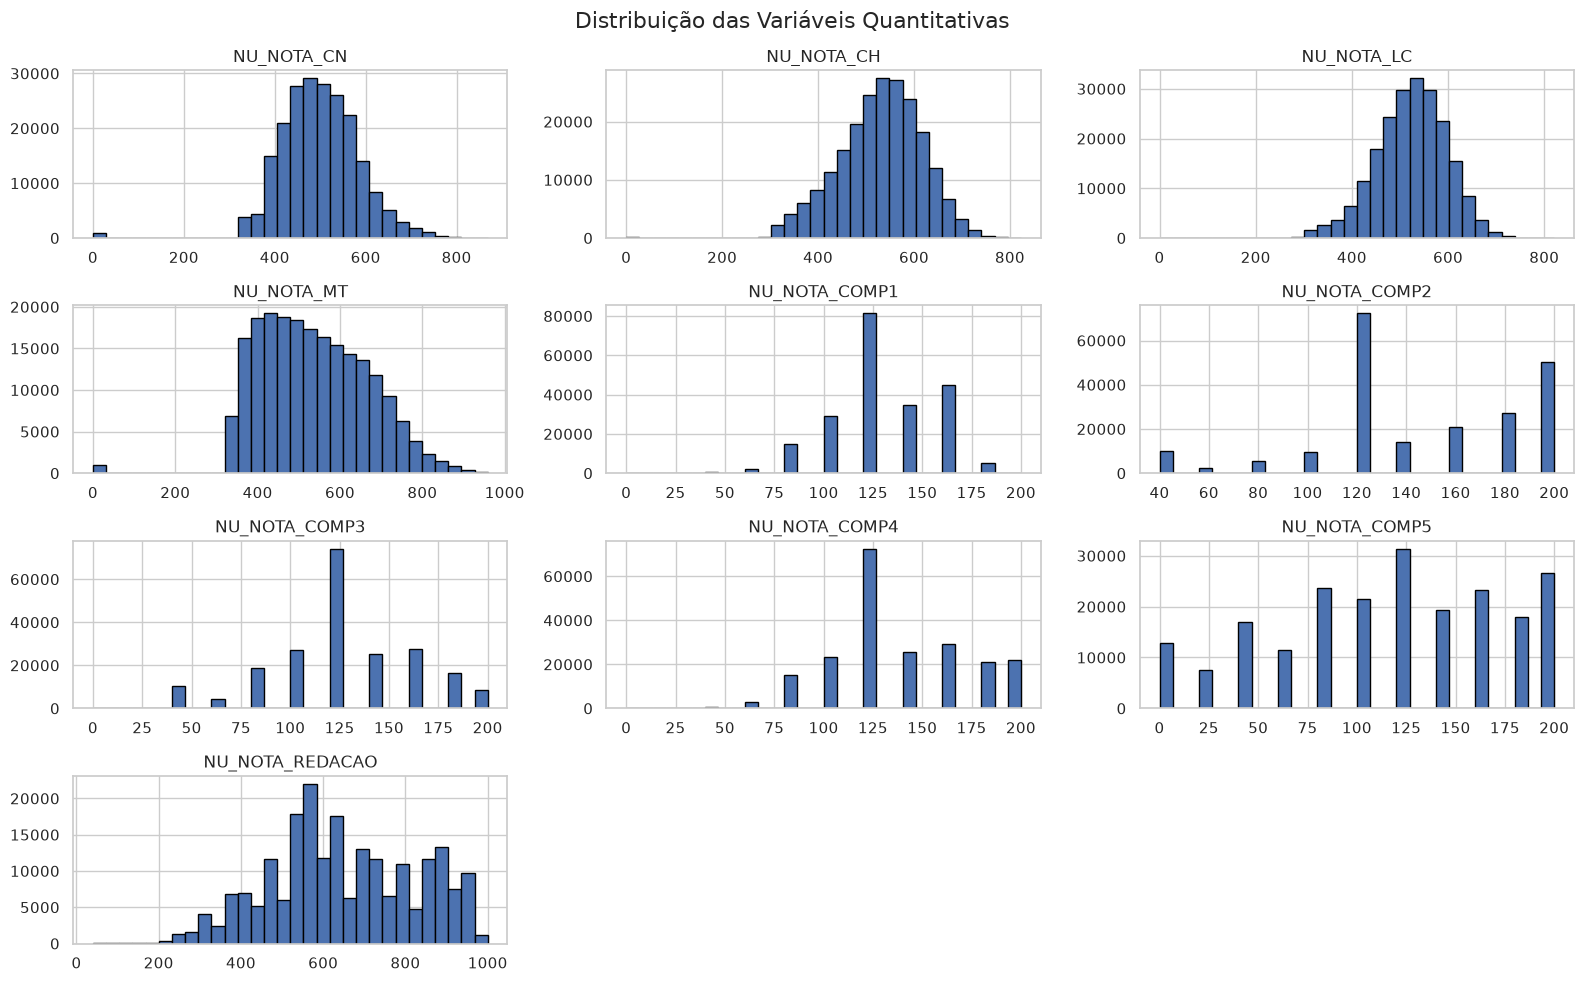

In [291]:
# Distribuição das variáveis quantitativas

df[variaveis_quantitativas].hist(
    figsize=(16, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribuição das Variáveis Quantitativas',
    fontsize=16
)

plt.tight_layout()
plt.show()

**Conclusao**

No grafico, observa-se formatos aproximadamente unimodais para NU_NOTA_CN, NU_NOTA_CH e NU_NOTA_LC.

NU_NOTA_MT apresenta uma assimétrica à direita.

NU_NOTA_REDACAO apresenta uma distribuição com vários picos isolados, decorrentes de sua composicao original.

In [292]:
from scipy import stats

# ── Estatísticas de forma: assimetria e curtose ───────────────────────────────
#
# Referências de interpretação:
#   Assimetria (skewness):
#     |skew| < 0.5  → aproximadamente simétrica
#     0.5 ≤ |skew| < 1.0  → moderadamente assimétrica
#     |skew| ≥ 1.0  → fortemente assimétrica
#
#   Curtose (excess kurtosis, padrão do scipy/pandas):
#     kurtosis ≈ 0  → mesocúrtica (similar à normal)
#     kurtosis > 0  → leptocúrtica (caudas pesadas)
#     kurtosis < 0  → platicúrtica (caudas leves)

forma = pd.DataFrame({
    'Assimetria': df[variaveis_quantitativas].skew().round(3),
    'Curtose':    df[variaveis_quantitativas].kurtosis().round(3),
})

# Classificação automática da assimetria
def classifica_assimetria(s):
    if abs(s) < 0.5:  return 'Simétrica'
    if abs(s) < 1.0:  return 'Mod. assimétrica'
    return 'Fort. assimétrica'

forma['Direção']       = forma['Assimetria'].apply(lambda s: 'Positiva' if s > 0 else 'Negativa')
forma['Classificação'] = forma['Assimetria'].apply(classifica_assimetria)

print("Estatísticas de forma das variáveis quantitativas:")
print(forma.to_string())
print()



Estatísticas de forma das variáveis quantitativas:
                 Assimetria  Curtose   Direção     Classificação
NU_NOTA_CN           -0.502    4.341  Negativa  Mod. assimétrica
NU_NOTA_CH           -0.414    0.843  Negativa         Simétrica
NU_NOTA_LC           -0.343    0.503  Negativa         Simétrica
NU_NOTA_MT            0.100    0.395  Positiva         Simétrica
NU_NOTA_COMP1        -0.141   -0.178  Negativa         Simétrica
NU_NOTA_COMP2        -0.424   -0.399  Negativa         Simétrica
NU_NOTA_COMP3        -0.142    0.025  Negativa         Simétrica
NU_NOTA_COMP4         0.191   -0.538  Positiva         Simétrica
NU_NOTA_COMP5        -0.258   -0.878  Negativa         Simétrica
NU_NOTA_REDACAO      -0.023   -0.775  Negativa         Simétrica



**Observação da EDA — Assimetria, Curtose e Bimodalidade**

O coeficiente de assimetria calculado diretamente nos dados é 0.073, ou seja, praticamente zero.
Portanto, estatisticamente, NU_NOTA_MT é aproximadamente simétrica segundo esse indicador.

- **`NU_NOTA_REDACAO`:** curtose negativa indica distribuição platicúrtica —
  notas mais espalhadas e sem concentração acentuada na média.

A decisão sobre transformações da variável-alvo será tomada no notebook de
feature engineering, após a definição formal do problema preditivo.


**Conclusão da análise univariada:**

Os gráficos revelam o perfil predominante dos candidatos presentes no ENEM 2023:
- Verificar se há desequilíbrio por sexo (padrão histórico: maioria feminina).
- Distribuição racial: verificar representação de pardos e pretos em relação ao censo.
- Escola: dentre os concluintes de 2023, verificar proporção pública vs. privada.
- Faixa etária: concentração nas faixas 17-20 anos, com cauda longa de adultos.
- Situação de conclusão: registrar proporção de "já concluiu" vs. concluintes atuais.

#### 1.9 Análise da Relação entre as Variáveis



Após analisar individualmente a distribuição das variáveis quantitativas, esta etapa busca investigar como as variáveis se comportam em conjunto. O objetivo é identificar possíveis relações, associações ou padrões entre as características dos participantes e seus respectivos resultados no ENEM.

A análise será realizada inicialmente por meio da comparação entre variáveis quantitativas, buscando verificar se alterações nos valores de uma variável estão associadas a alterações em outra. Essa investigação poderá revelar relações relevantes entre as notas das diferentes áreas de conhecimento e entre as competências da redação e sua nota final.

Neste momento, a análise tem caráter exploratório. A identificação de uma relação entre duas variáveis não implica, necessariamente, uma relação de causalidade. Os padrões encontrados serão utilizados para orientar as etapas posteriores da EDA e, posteriormente, a construção das variáveis e dos modelos preditivos.

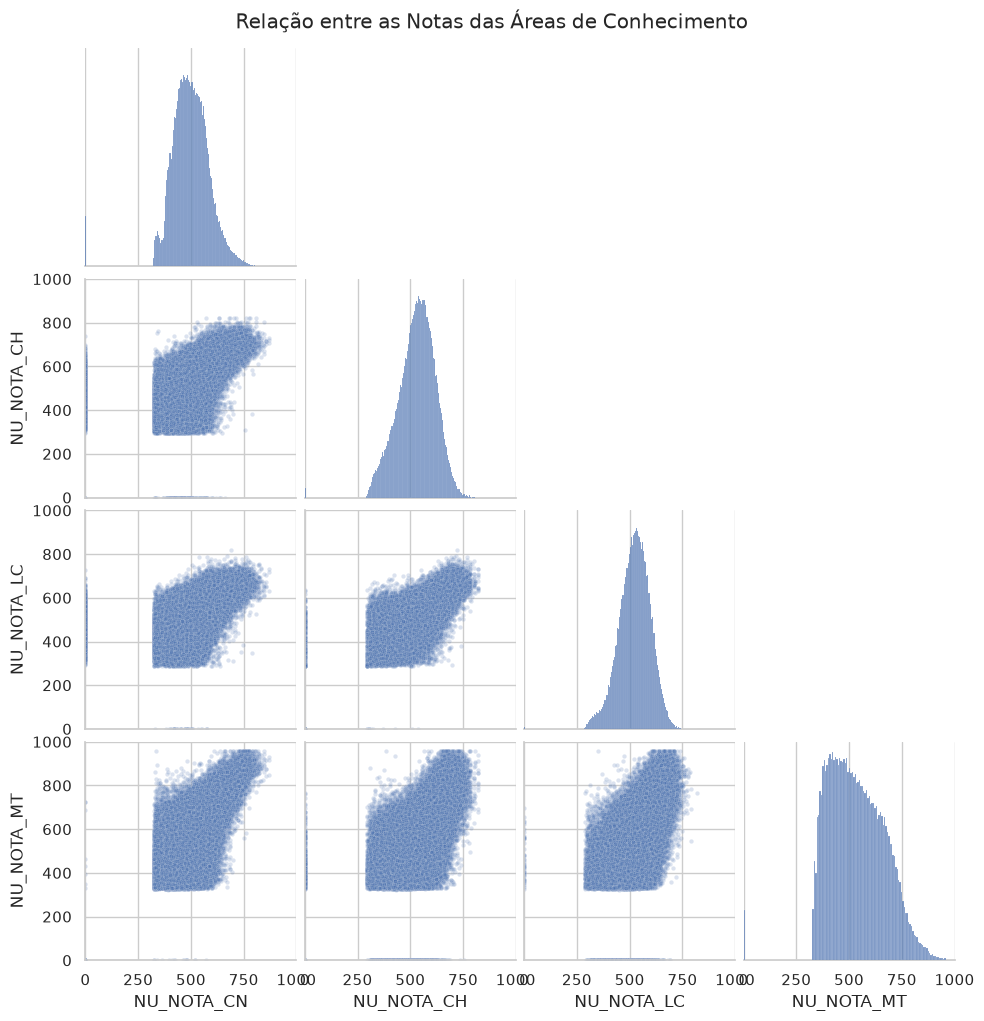

In [293]:
# Relação entre as notas das áreas de conhecimento
# Todos os gráficos utilizam a mesma escala: 0 a 1000

variaveis_areas = [
    'NU_NOTA_CN',
    'NU_NOTA_CH',
    'NU_NOTA_LC',
    'NU_NOTA_MT'
]

g = sns.pairplot(
    df[variaveis_areas],
    corner=True,
    plot_kws={'alpha': 0.2, 's': 10}
)

# Padroniza a escala de todos os eixos
for ax in g.axes.flat:
    if ax is not None:
        ax.set_xlim(0, 1000)
        ax.set_ylim(0, 1000)

g.figure.suptitle(
    'Relação entre as Notas das Áreas de Conhecimento',
    y=1.02
)

plt.show()

#### 1.10 Observaçao das Variaveis Socioeconomicas


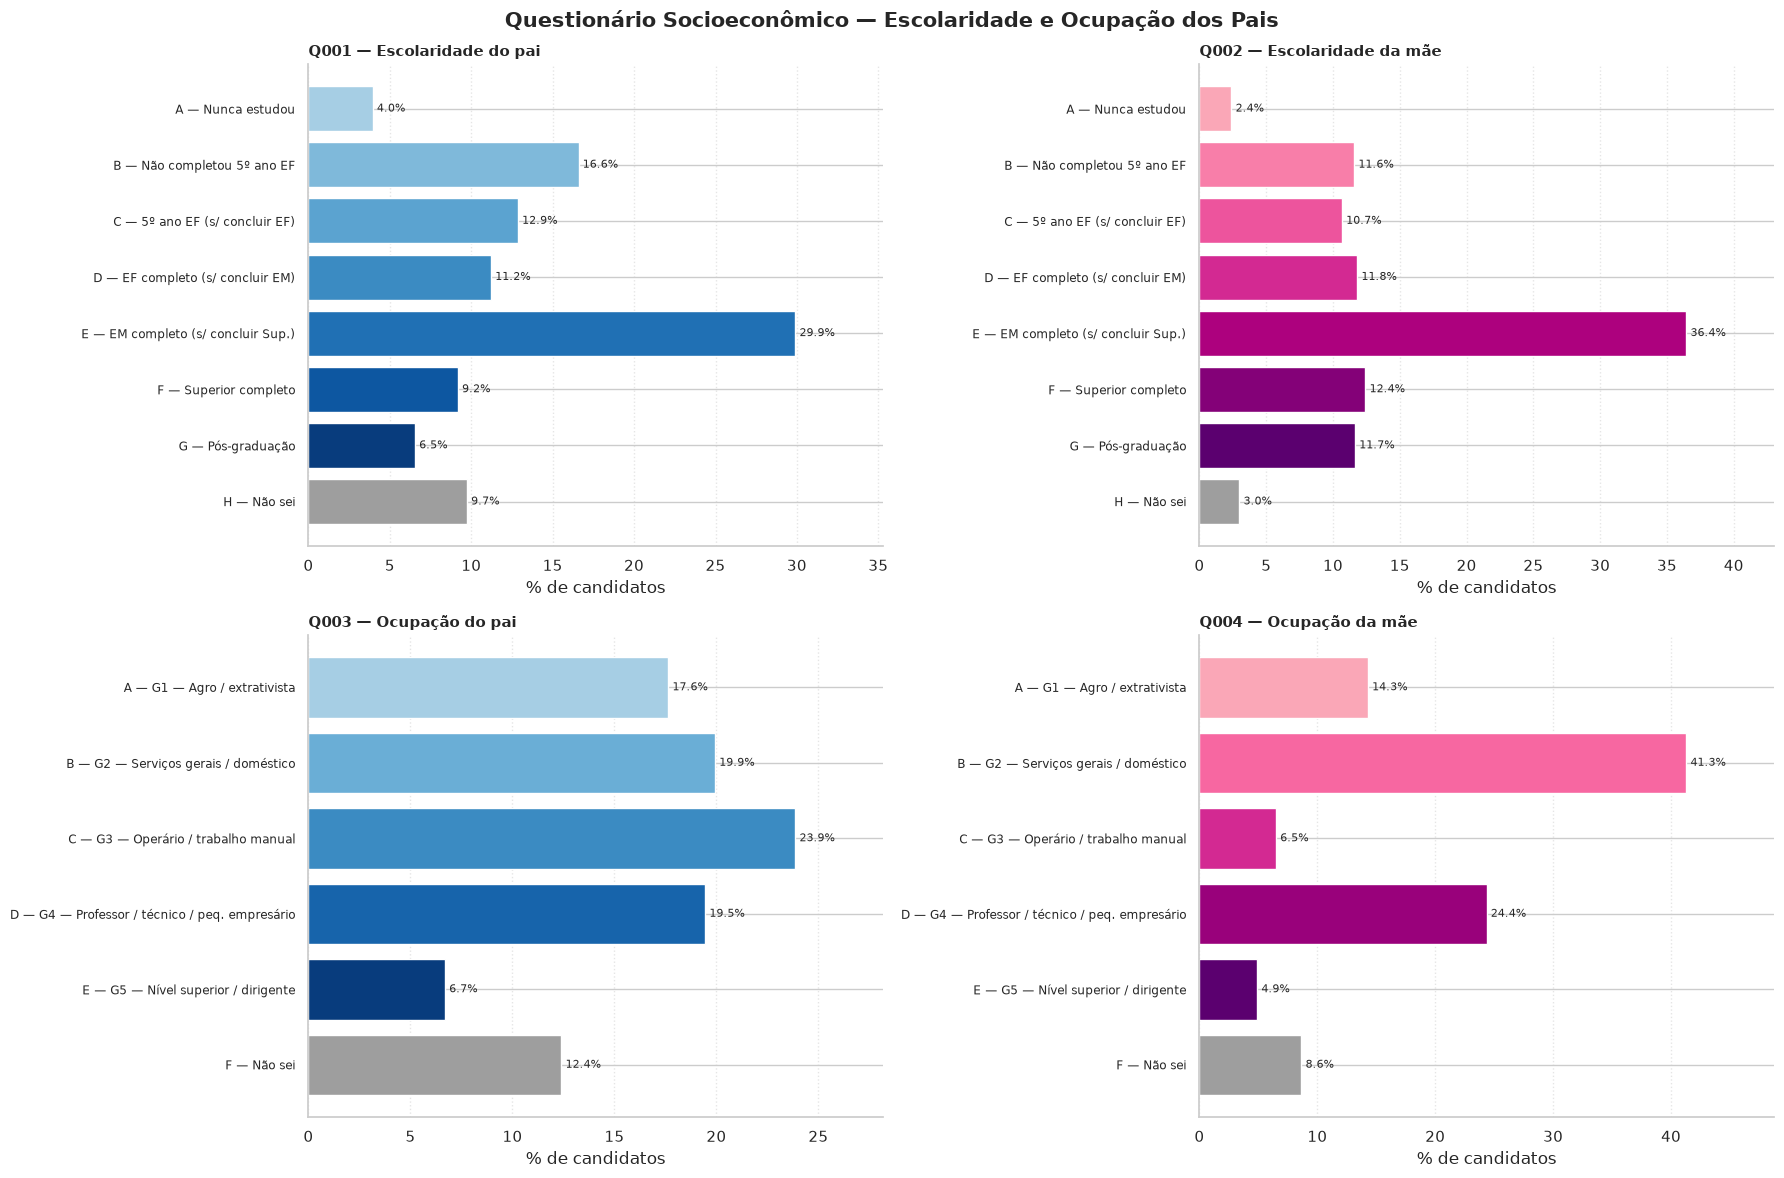

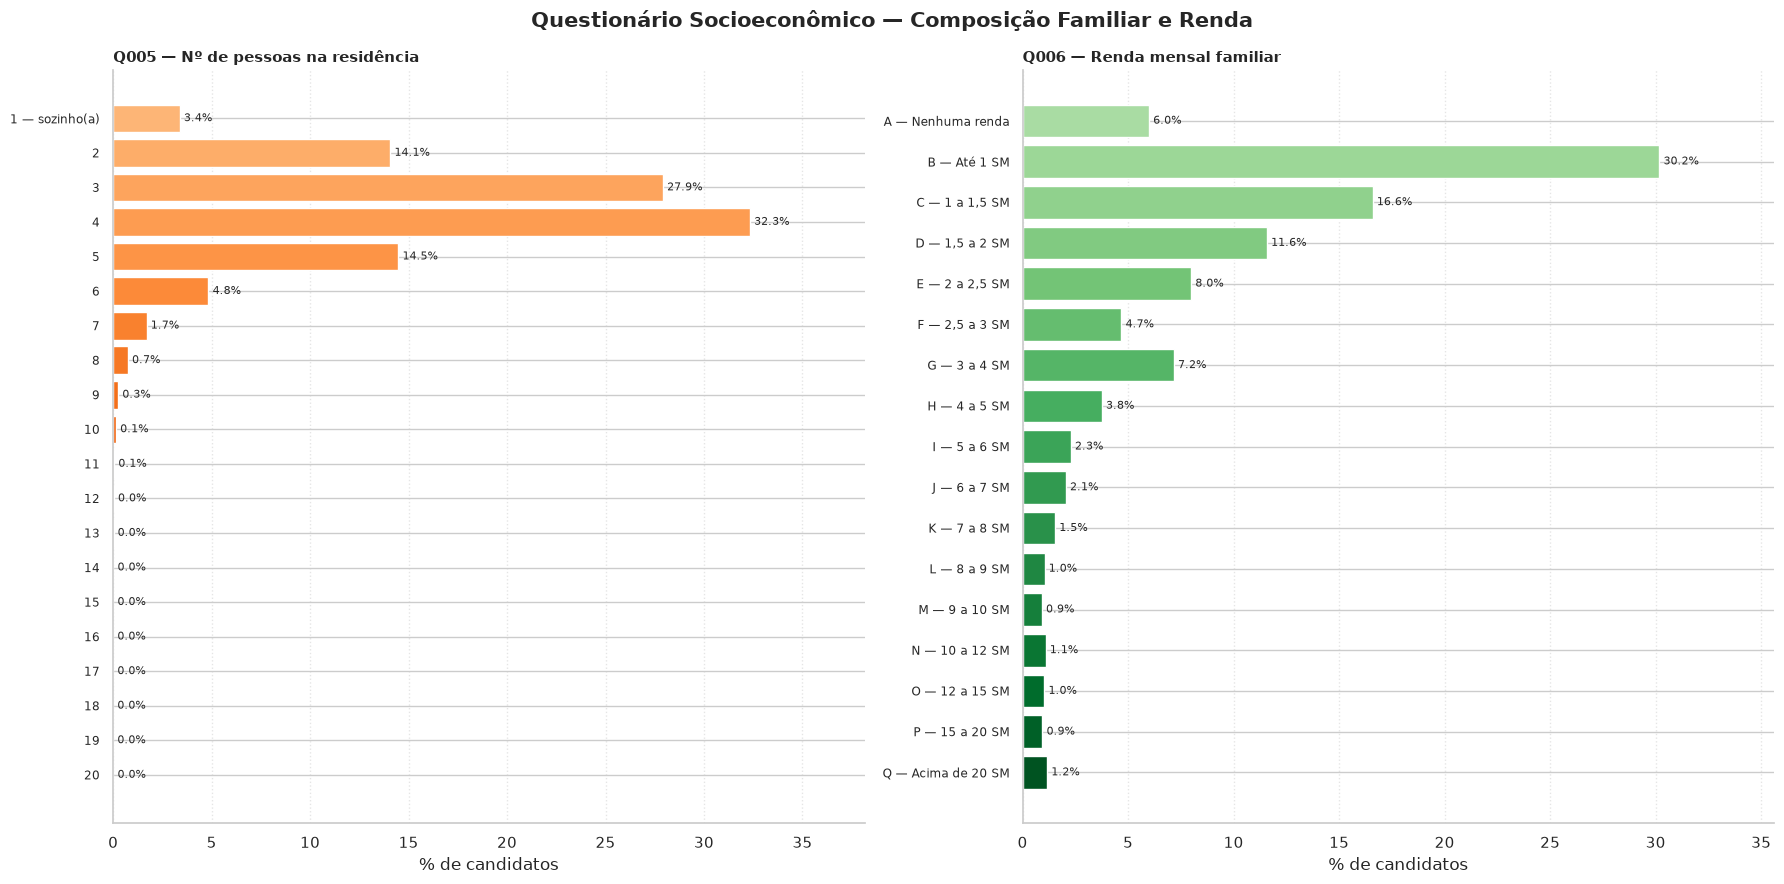

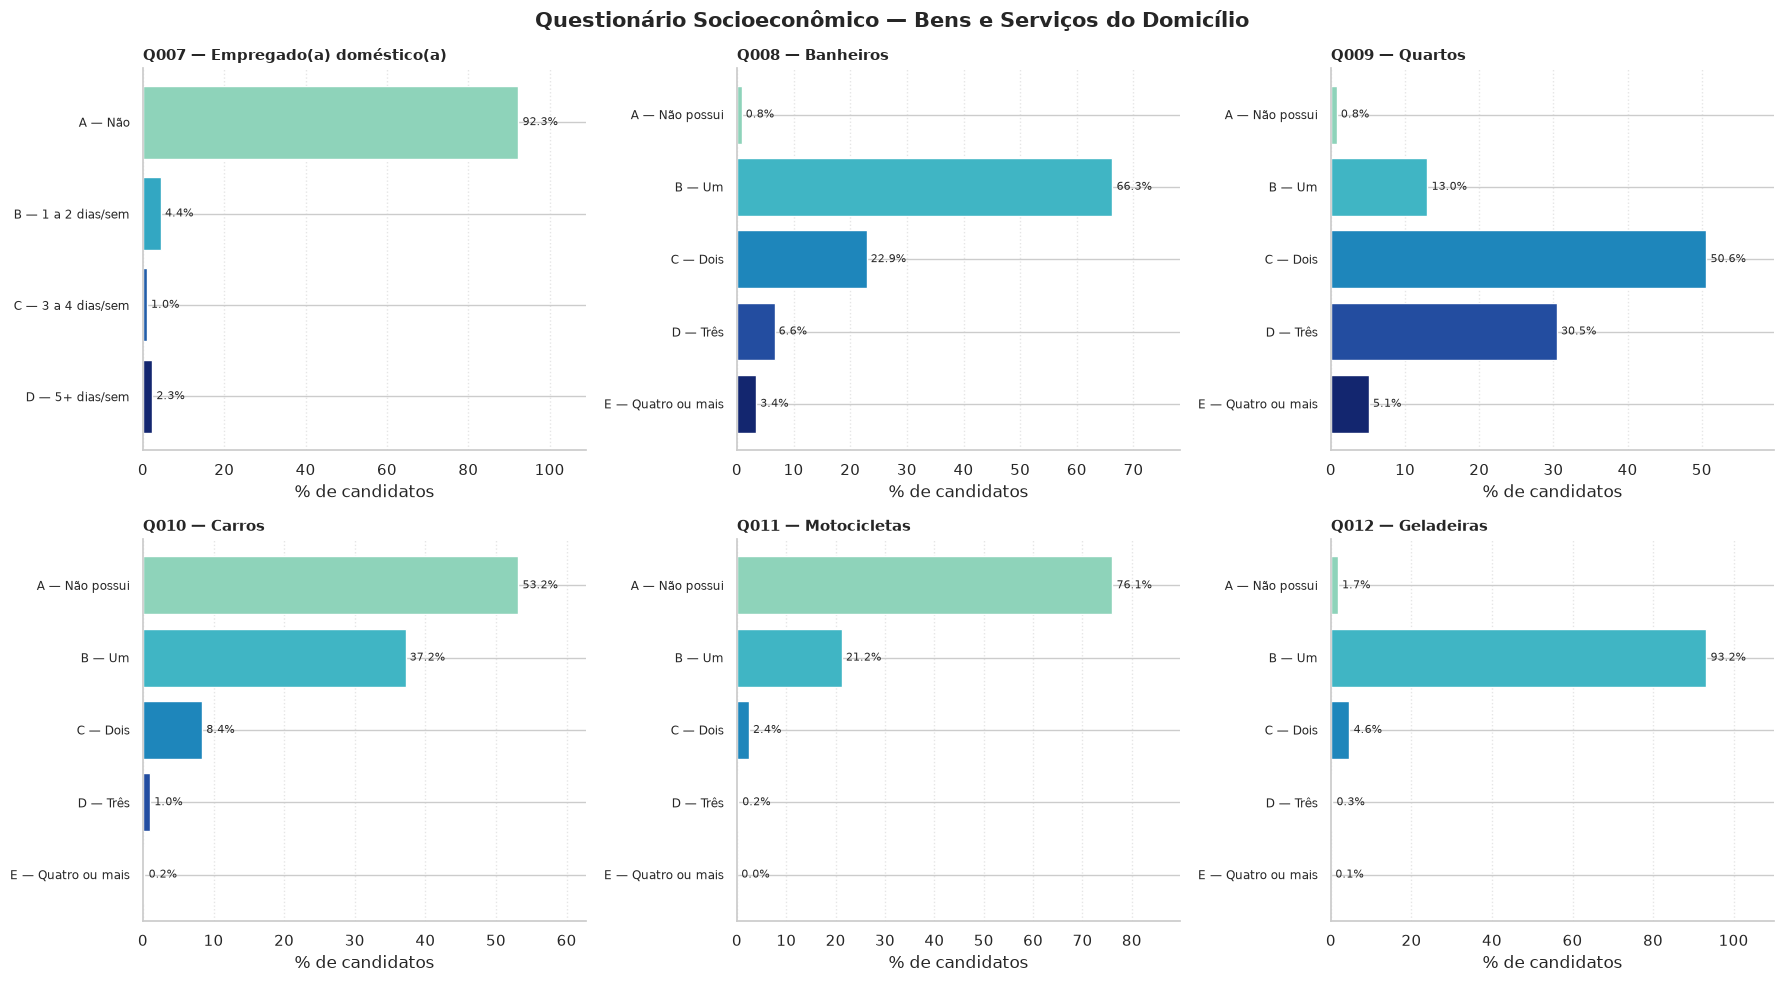

In [294]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ══════════════════════════════════════════════════════════════════════════════
# Rótulos curtos para visualização (mesma codificação do dicionário INEP 2023)
# ══════════════════════════════════════════════════════════════════════════════
ESC_CURTO = {
    'A': 'Nunca estudou',
    'B': 'Não completou 5º ano EF',
    'C': '5º ano EF (s/ concluir EF)',
    'D': 'EF completo (s/ concluir EM)',
    'E': 'EM completo (s/ concluir Sup.)',
    'F': 'Superior completo',
    'G': 'Pós-graduação',
    'H': 'Não sei',
}
OCUP_CURTO = {
    'A': 'G1 — Agro / extrativista',
    'B': 'G2 — Serviços gerais / doméstico',
    'C': 'G3 — Operário / trabalho manual',
    'D': 'G4 — Professor / técnico / peq. empresário',
    'E': 'G5 — Nível superior / dirigente',
    'F': 'Não sei',
}
PESSOAS_CURTO = {1: 'sozinho(a)', **{i: '' for i in range(2, 21)}}
RENDA_CURTO = {   # SM = salário mínimo de 2023 (R$ 1.320)
    'A': 'Nenhuma renda', 'B': 'Até 1 SM',   'C': '1 a 1,5 SM',  'D': '1,5 a 2 SM',
    'E': '2 a 2,5 SM',    'F': '2,5 a 3 SM', 'G': '3 a 4 SM',    'H': '4 a 5 SM',
    'I': '5 a 6 SM',      'J': '6 a 7 SM',   'K': '7 a 8 SM',    'L': '8 a 9 SM',
    'M': '9 a 10 SM',     'N': '10 a 12 SM', 'O': '12 a 15 SM',  'P': '15 a 20 SM',
    'Q': 'Acima de 20 SM',
}
EMPREGADA_CURTO = {'A': 'Não', 'B': '1 a 2 dias/sem', 'C': '3 a 4 dias/sem', 'D': '5+ dias/sem'}
BENS_CURTO = {'A': 'Não possui', 'B': 'Um', 'C': 'Dois', 'D': 'Três', 'E': 'Quatro ou mais'}

# Categorias NÃO ordinais (recebem cor neutra)
NAO_ORDINAL = {'Q001': ['H'], 'Q002': ['H'], 'Q003': ['F'], 'Q004': ['F']}

COR_NEUTRA = '#9e9e9e'


# ══════════════════════════════════════════════════════════════════════════════
# Função de plotagem
# ══════════════════════════════════════════════════════════════════════════════
def plot_dist(ax, var, mapa, titulo, cmap_name):
    s = df[var]
    total = len(s)
    n_nulos = int(s.isna().sum())

    s_val = s.dropna()
    if pd.api.types.is_float_dtype(s_val):      # Q005 pode vir como float
        s_val = s_val.astype(int)

    cont = s_val.value_counts()
    ordem  = [k for k in mapa if k in cont.index]
    extras = sorted([k for k in cont.index if k not in mapa], key=str)
    cont = cont.reindex(ordem + extras)

    # Rótulos e percentuais
    labels = [f"{k} — {mapa[k]}" if mapa.get(k) else
              (f"{k}" if k in mapa else f"{k} — ⚠ fora do dicionário")
              for k in cont.index]
    pct = list(cont.values / total * 100)

    # Cores: gradiente para categorias ordinais, cinza para 'Não sei'/extras/NaN
    neutros = set(NAO_ORDINAL.get(var, [])) | set(extras)
    n_ord = sum(1 for k in cont.index if k not in neutros)
    gradiente = iter(plt.get_cmap(cmap_name)(np.linspace(0.35, 0.95, max(n_ord, 1))))
    cores = [COR_NEUTRA if k in neutros else next(gradiente) for k in cont.index]

    if n_nulos > 0:
        labels.append('NaN — Não respondeu')
        pct.append(n_nulos / total * 100)
        cores.append('#d9d9d9')

    bars = ax.barh(labels, pct, color=cores, edgecolor='white')
    ax.invert_yaxis()                                   # 1ª categoria no topo
    ax.bar_label(bars, labels=[f'{p:.1f}%' for p in pct], padding=3, fontsize=8)
    ax.set_xlim(0, max(pct) * 1.18)
    ax.set_title(f'{var} — {titulo}', fontsize=11, fontweight='bold', loc='left')
    ax.set_xlabel('% de candidatos')
    ax.tick_params(axis='y', labelsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)


# ══════════════════════════════════════════════════════════════════════════════
# PAINEL 1 — Escolaridade e ocupação dos pais (Q001 a Q004)
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Questionário Socioeconômico — Escolaridade e Ocupação dos Pais',
             fontsize=15, fontweight='bold')
plot_dist(axes[0, 0], 'Q001', ESC_CURTO,  'Escolaridade do pai',  'Blues')
plot_dist(axes[0, 1], 'Q002', ESC_CURTO,  'Escolaridade da mãe',  'RdPu')
plot_dist(axes[1, 0], 'Q003', OCUP_CURTO, 'Ocupação do pai',      'Blues')
plot_dist(axes[1, 1], 'Q004', OCUP_CURTO, 'Ocupação da mãe',      'RdPu')
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PAINEL 2 — Composição familiar e renda (Q005 e Q006)
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
fig.suptitle('Questionário Socioeconômico — Composição Familiar e Renda',
             fontsize=15, fontweight='bold')
plot_dist(axes[0], 'Q005', PESSOAS_CURTO, 'Nº de pessoas na residência', 'Oranges')
plot_dist(axes[1], 'Q006', RENDA_CURTO,   'Renda mensal familiar',       'Greens')
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# PAINEL 3 — Bens e serviços do domicílio (Q007 a Q012)
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Questionário Socioeconômico — Bens e Serviços do Domicílio',
             fontsize=15, fontweight='bold')
plot_dist(axes[0, 0], 'Q007', EMPREGADA_CURTO, 'Empregado(a) doméstico(a)', 'YlGnBu')
plot_dist(axes[0, 1], 'Q008', BENS_CURTO,      'Banheiros',                 'YlGnBu')
plot_dist(axes[0, 2], 'Q009', BENS_CURTO,      'Quartos',                   'YlGnBu')
plot_dist(axes[1, 0], 'Q010', BENS_CURTO,      'Carros',                    'YlGnBu')
plot_dist(axes[1, 1], 'Q011', BENS_CURTO,      'Motocicletas',              'YlGnBu')
plot_dist(axes[1, 2], 'Q012', BENS_CURTO,      'Geladeiras',                'YlGnBu')
plt.tight_layout()
plt.show()


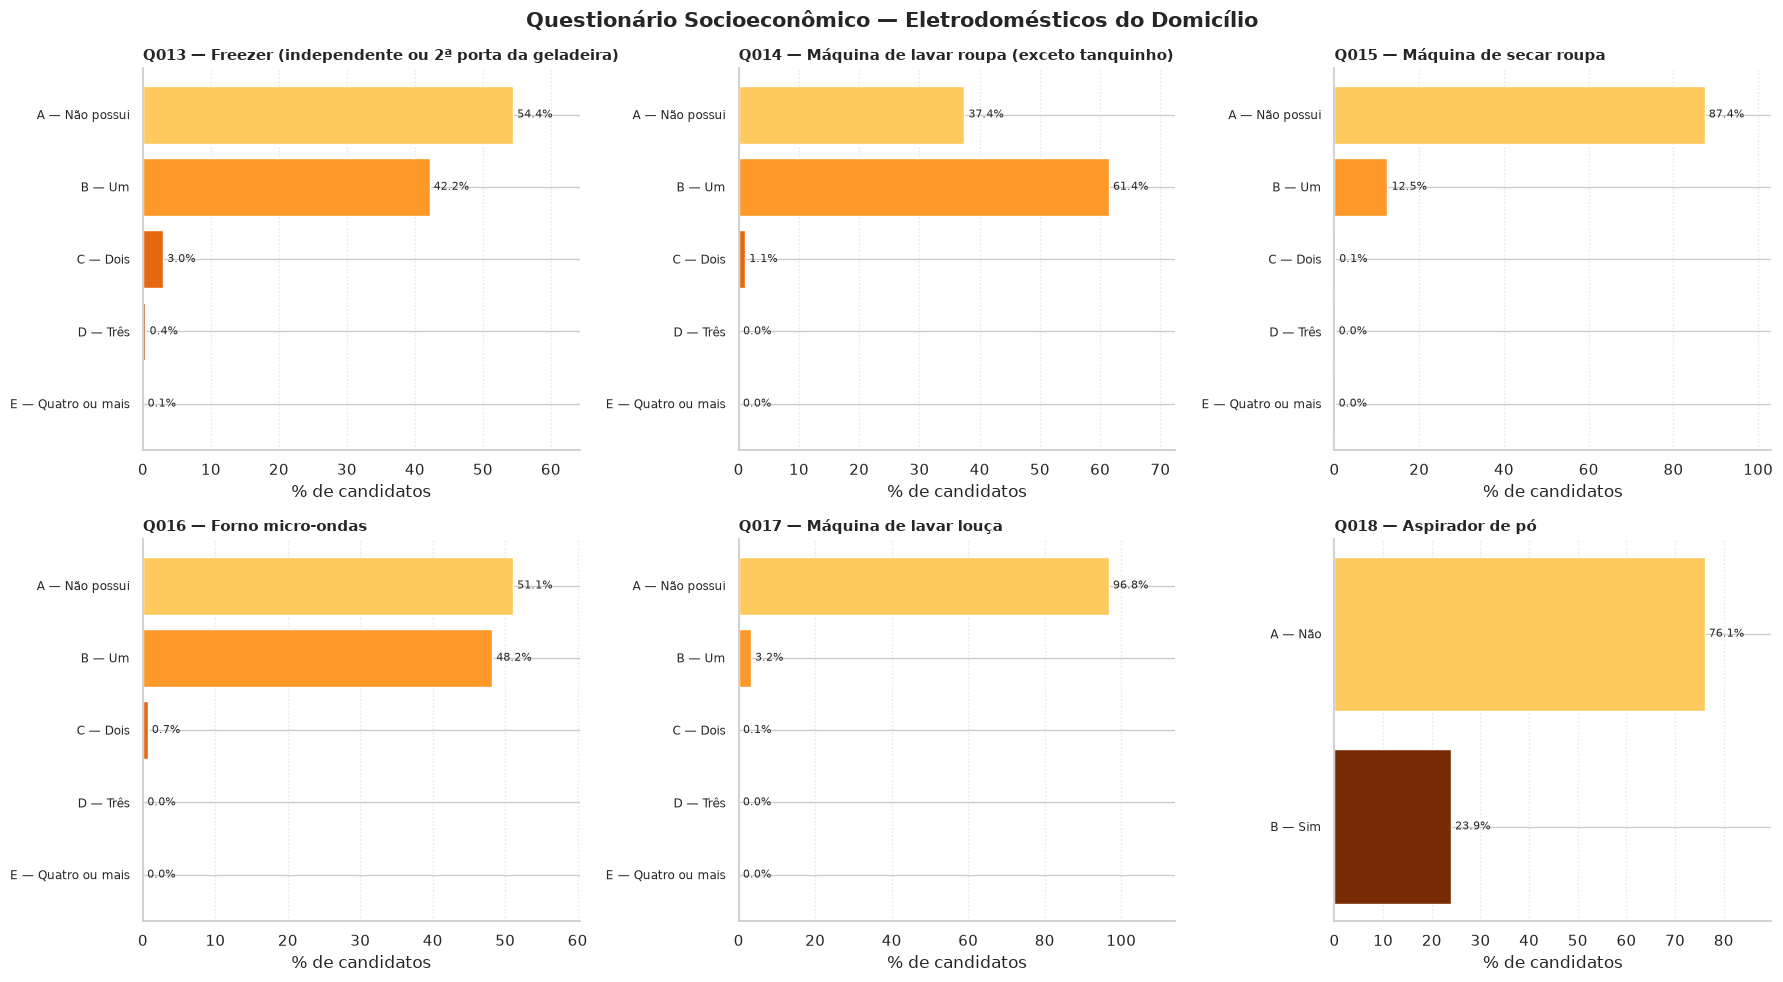

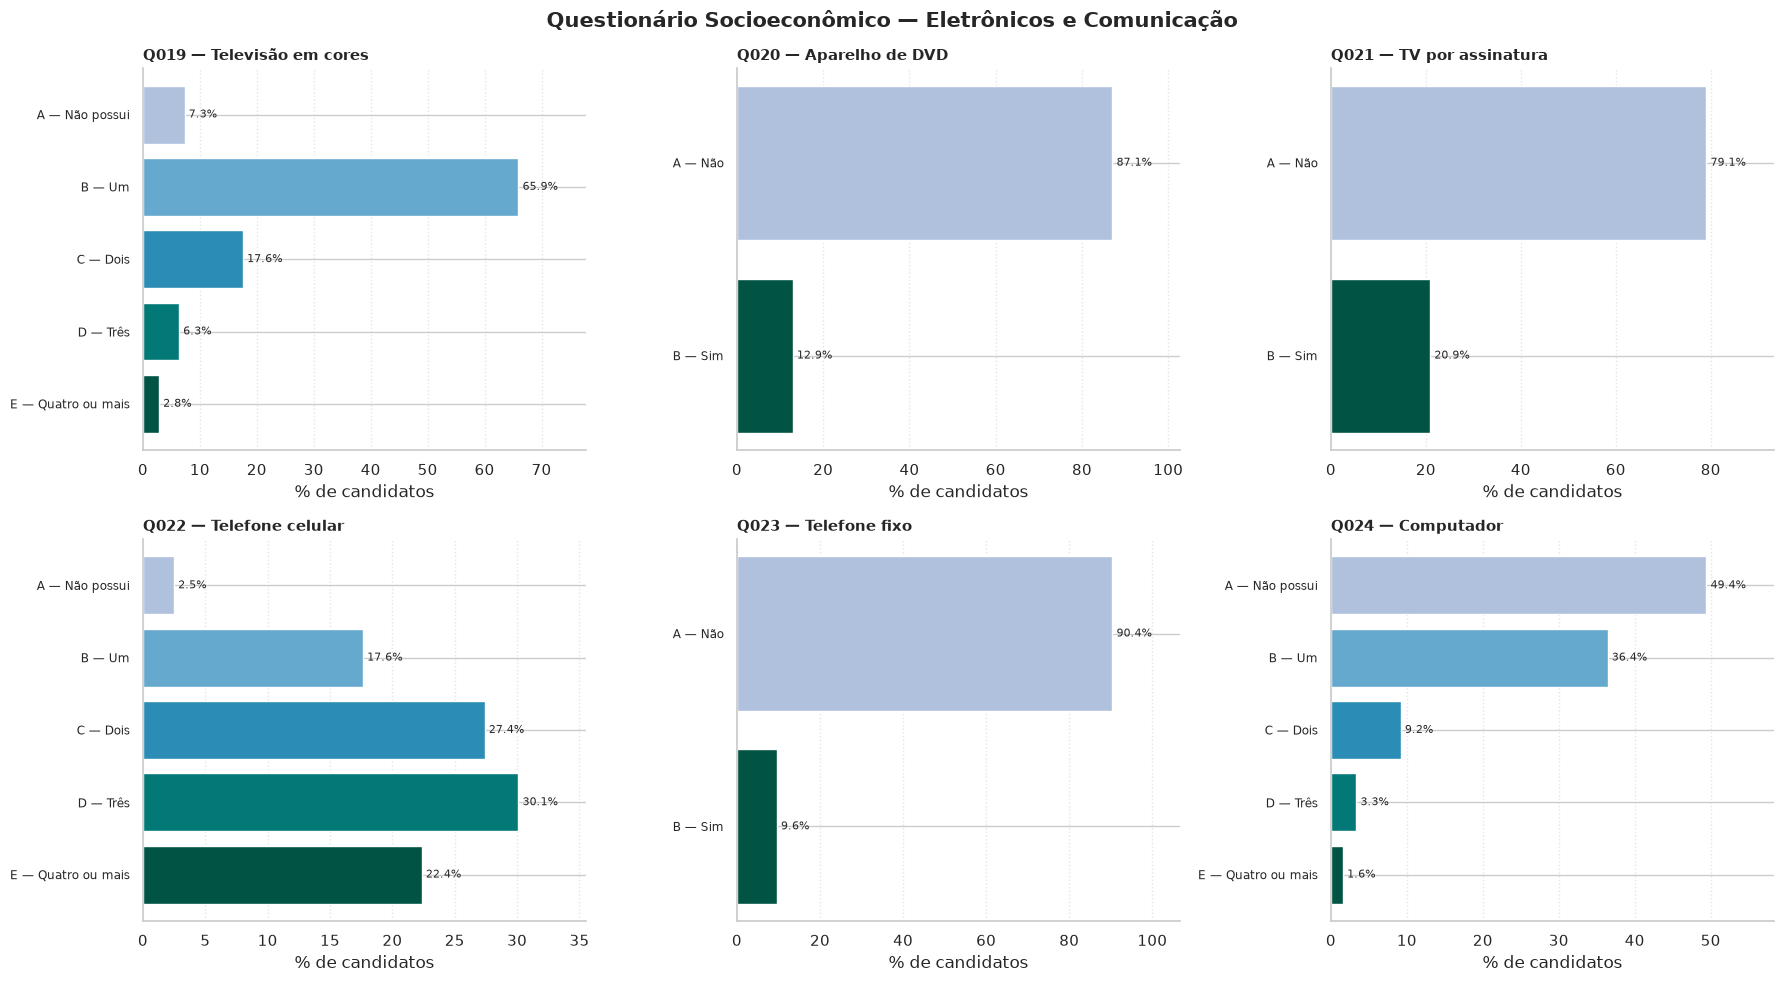

In [295]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ══════════════════════════════════════════════════════════════════════════════
# Rótulos curtos (dicionário INEP — ENEM 2023, Q013 a Q024)
# ══════════════════════════════════════════════════════════════════════════════
QTD_CURTO = {'A': 'Não possui', 'B': 'Um', 'C': 'Dois', 'D': 'Três', 'E': 'Quatro ou mais'}
SIM_NAO   = {'A': 'Não', 'B': 'Sim'}

DICIONARIO_Q13_24 = {
    'Q013': ('Freezer (independente ou 2ª porta da geladeira)', QTD_CURTO),
    'Q014': ('Máquina de lavar roupa (exceto tanquinho)',       QTD_CURTO),
    'Q015': ('Máquina de secar roupa',                          QTD_CURTO),
    'Q016': ('Forno micro-ondas',                               QTD_CURTO),
    'Q017': ('Máquina de lavar louça',                          QTD_CURTO),
    'Q018': ('Aspirador de pó',                                 SIM_NAO),
    'Q019': ('Televisão em cores',                              QTD_CURTO),
    'Q020': ('Aparelho de DVD',                                 SIM_NAO),
    'Q021': ('TV por assinatura',                               SIM_NAO),
    'Q022': ('Telefone celular',                                QTD_CURTO),
    'Q023': ('Telefone fixo',                                   SIM_NAO),
    'Q024': ('Computador',                                      QTD_CURTO),
}

NAO_ORDINAL = {}          # neste bloco todas as categorias são ordinais
COR_NEUTRA  = '#9e9e9e'


# ══════════════════════════════════════════════════════════════════════════════
# Função de plotagem (mesma da célula Q001–Q012)
# ══════════════════════════════════════════════════════════════════════════════
def plot_dist(ax, var, mapa, titulo, cmap_name):
    s = df[var]
    total = len(s)
    n_nulos = int(s.isna().sum())

    s_val = s.dropna()
    if pd.api.types.is_float_dtype(s_val):
        s_val = s_val.astype(int)

    cont = s_val.value_counts()
    ordem  = [k for k in mapa if k in cont.index]
    extras = sorted([k for k in cont.index if k not in mapa], key=str)
    cont = cont.reindex(ordem + extras)

    labels = [f"{k} — {mapa[k]}" if mapa.get(k) else
              (f"{k}" if k in mapa else f"{k} — ⚠ fora do dicionário")
              for k in cont.index]
    pct = list(cont.values / total * 100)

    neutros = set(NAO_ORDINAL.get(var, [])) | set(extras)
    n_ord = sum(1 for k in cont.index if k not in neutros)
    gradiente = iter(plt.get_cmap(cmap_name)(np.linspace(0.35, 0.95, max(n_ord, 1))))
    cores = [COR_NEUTRA if k in neutros else next(gradiente) for k in cont.index]

    if n_nulos > 0:
        labels.append('NaN — Não respondeu')
        pct.append(n_nulos / total * 100)
        cores.append('#d9d9d9')

    bars = ax.barh(labels, pct, color=cores, edgecolor='white')
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f'{p:.1f}%' for p in pct], padding=3, fontsize=8)
    ax.set_xlim(0, max(pct) * 1.18)
    ax.set_title(f'{var} — {titulo}', fontsize=11, fontweight='bold', loc='left')
    ax.set_xlabel('% de candidatos')
    ax.tick_params(axis='y', labelsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)


def painel(variaveis, titulo_painel, cmap_name):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(titulo_painel, fontsize=15, fontweight='bold')
    for ax, var in zip(axes.flatten(), variaveis):
        if var in df.columns:
            titulo, mapa = DICIONARIO_Q13_24[var]
            plot_dist(ax, var, mapa, titulo, cmap_name)
        else:
            ax.text(0.5, 0.5, f'⚠ {var} não encontrada', ha='center', va='center')
            ax.axis('off')
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# PAINEL 1 — Eletrodomésticos (Q013 a Q018)
# ══════════════════════════════════════════════════════════════════════════════
painel(['Q013', 'Q014', 'Q015', 'Q016', 'Q017', 'Q018'],
       'Questionário Socioeconômico — Eletrodomésticos do Domicílio', 'YlOrBr')

# ══════════════════════════════════════════════════════════════════════════════
# PAINEL 2 — Eletrônicos e Comunicação (Q019 a Q024)
# ══════════════════════════════════════════════════════════════════════════════
painel(['Q019', 'Q020', 'Q021', 'Q022', 'Q023', 'Q024'],
       'Questionário Socioeconômico — Eletrônicos e Comunicação', 'PuBuGn')


**Conclusão da Análise de Bens:** 

A EDA demonstrou que as variáveis Q007 a Q025 possuem alta sobreposição visual com a Renda (Q006). Levanta-se a forte hipótese de que a maioria desses itens não agregará valor preditivo adicional. Esta hipótese será testada empiricamente no próximo caderno (Engenharia de Features) através de estudos de ablação algorítmica, visando a redução de dimensionalidade."

#### 1.11 Análise Bivariada: Perfil Demográfico × Notas



Esta seção investiga a relação entre as principais variáveis demográficas e o desempenho dos candidatos.
A análise bivariada é fundamental para identificar padrões de desigualdade e para compreender quais
características estão associadas a melhores ou piores resultados antes da construção de qualquer modelo.

As variáveis analisadas são: sexo, cor/raça e tipo de escola (para concluintes de 2023).
Notas zero são excluídas das visualizações para não distorcer a distribuição.

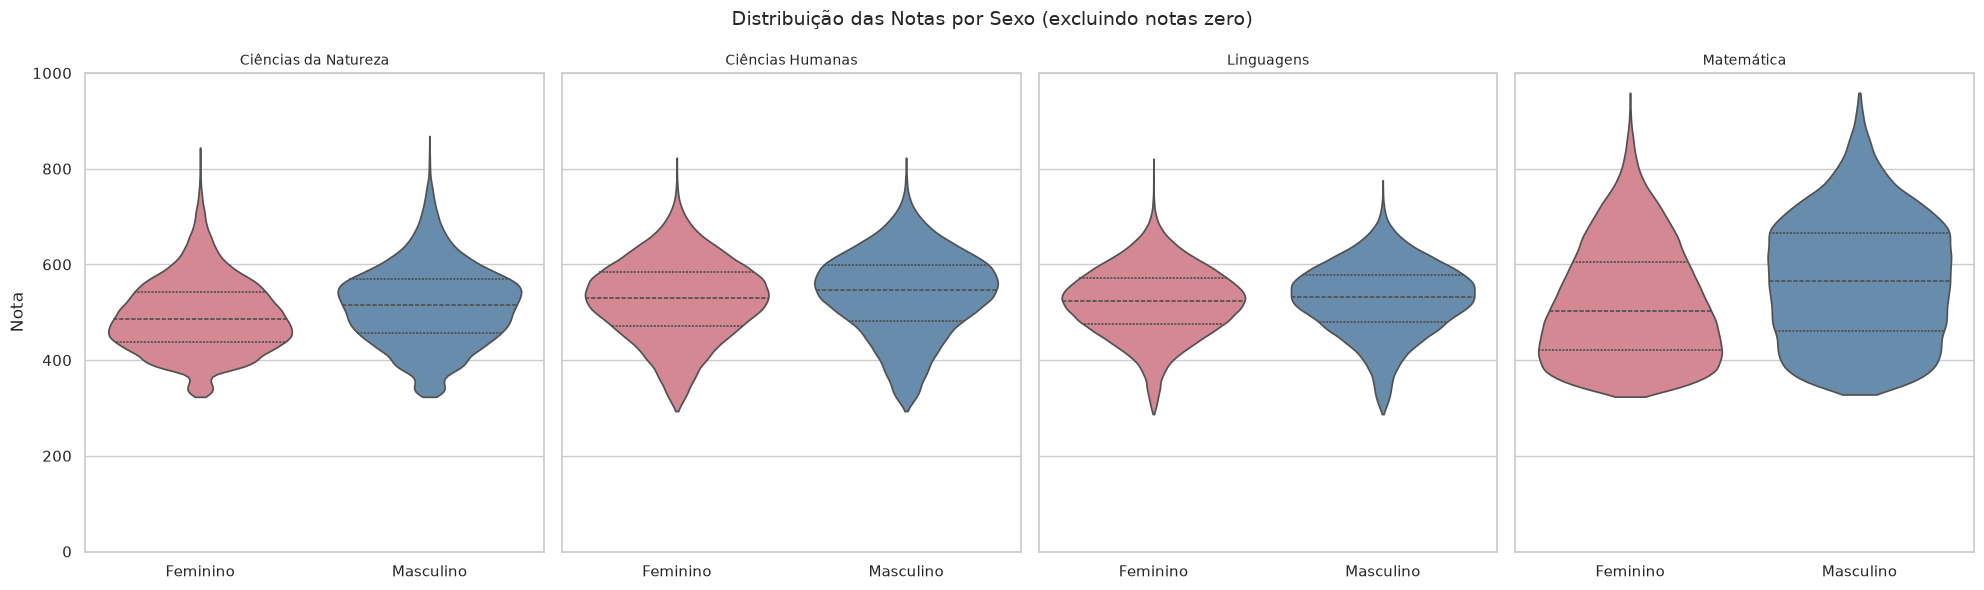

Médias por sexo (excluindo notas zero):
           Ciências da Natureza  Ciências Humanas  Linguagens  Matemática
Sexo                                                                     
Feminino                  492.9             525.9       521.4       520.1
Masculino                 515.7             537.9       526.8       566.8


In [296]:
notas = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT']
titulos = ['Ciências da Natureza', 'Ciências Humanas', 'Linguagens', 'Matemática']

df_plot = df.copy()
df_plot['Sexo'] = df_plot['TP_SEXO'].map({'M': 'Masculino', 'F': 'Feminino'})

fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
fig.suptitle('Distribuição das Notas por Sexo (excluindo notas zero)', fontsize=14)

for i, (nota, titulo) in enumerate(zip(notas, titulos)):
    ax = axes[i]
    sub = df_plot[df_plot[nota] > 0]
    sns.violinplot(
        data=sub, x='Sexo', y=nota,
        order=['Feminino', 'Masculino'],
        palette={'Feminino': '#E07B8A', 'Masculino': '#5B8DB8'},
        ax=ax, inner='quartile', cut=0
    )
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Nota' if i == 0 else '')
    ax.set_ylim(0, 1000)

plt.tight_layout()
plt.show()

print("Médias por sexo (excluindo notas zero):")
medias_sexo = (
    df_plot[df_plot[notas].gt(0).all(axis=1)]
    .groupby('Sexo')[notas].mean().round(1)
)
medias_sexo.columns = titulos
print(medias_sexo.to_string())

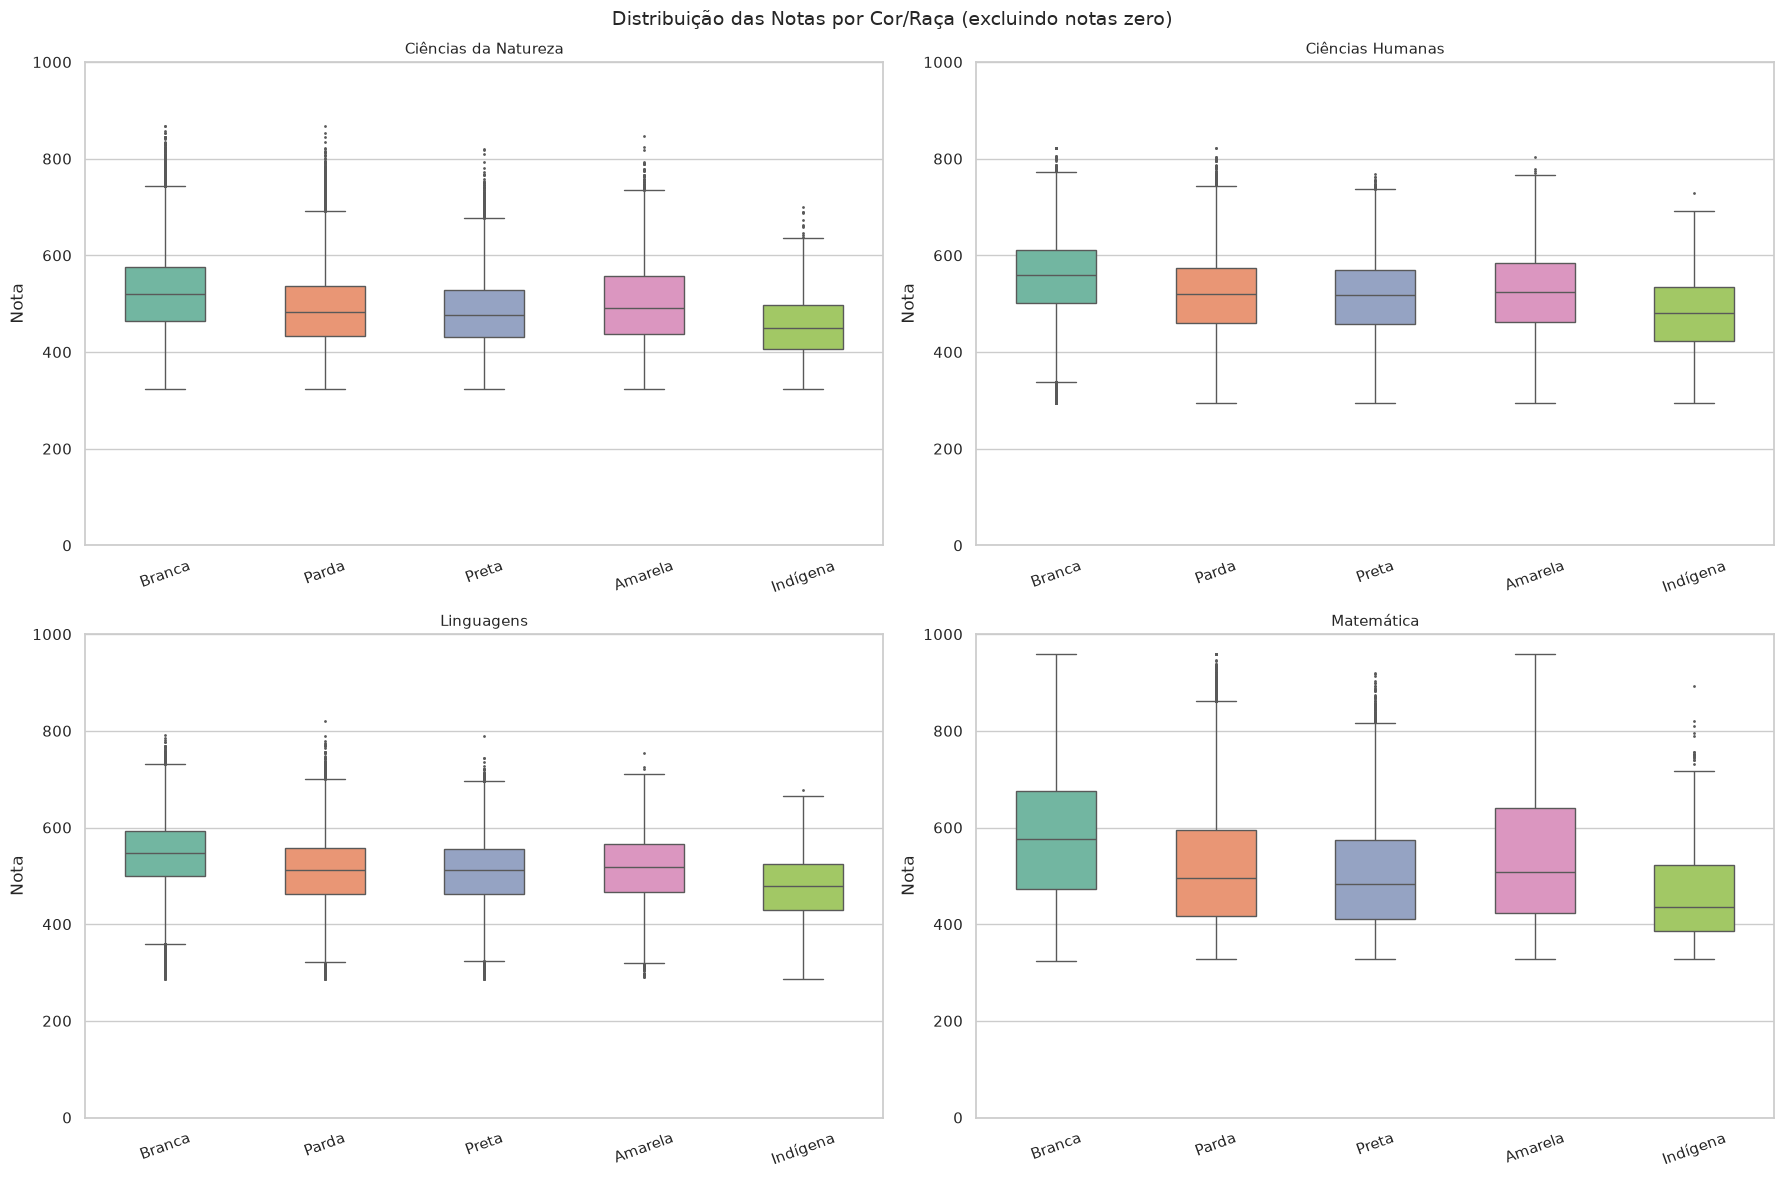

Médias por cor/raça (excluindo notas zero):
          Ciências da Natureza  Ciências Humanas  Linguagens  Matemática
Cor/Raça                                                                
Branca                   523.3             552.4       543.4       577.1
Parda                    487.4             515.4       509.6       513.1
Preta                    481.0             512.3       507.5       499.1
Amarela                  502.3             521.7       515.3       539.0
Indígena                 455.3             480.4       475.5       461.9


In [297]:
labels_raca_biv = {1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena'}
ordem_raca_biv  = ['Branca', 'Parda', 'Preta', 'Amarela', 'Indígena']

df_raca = df[df['TP_COR_RACA'].isin(labels_raca_biv)].copy()
df_raca['Cor/Raça'] = df_raca['TP_COR_RACA'].map(labels_raca_biv)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Distribuição das Notas por Cor/Raça (excluindo notas zero)', fontsize=14)

for i, (nota, titulo) in enumerate(zip(notas, titulos)):
    ax = axes[i // 2][i % 2]
    sub = df_raca[df_raca[nota] > 0]
    sns.boxplot(
        data=sub, x='Cor/Raça', y=nota,
        order=ordem_raca_biv, palette='Set2',
        ax=ax, width=0.5, fliersize=1
    )
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Nota')
    ax.set_ylim(0, 1000)
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

print("Médias por cor/raça (excluindo notas zero):")
medias_raca_biv = (
    df_raca[df_raca[notas].gt(0).all(axis=1)]
    .groupby('Cor/Raça')[notas].mean().round(1)
)
medias_raca_biv.columns = titulos
print(medias_raca_biv.reindex(ordem_raca_biv).to_string())

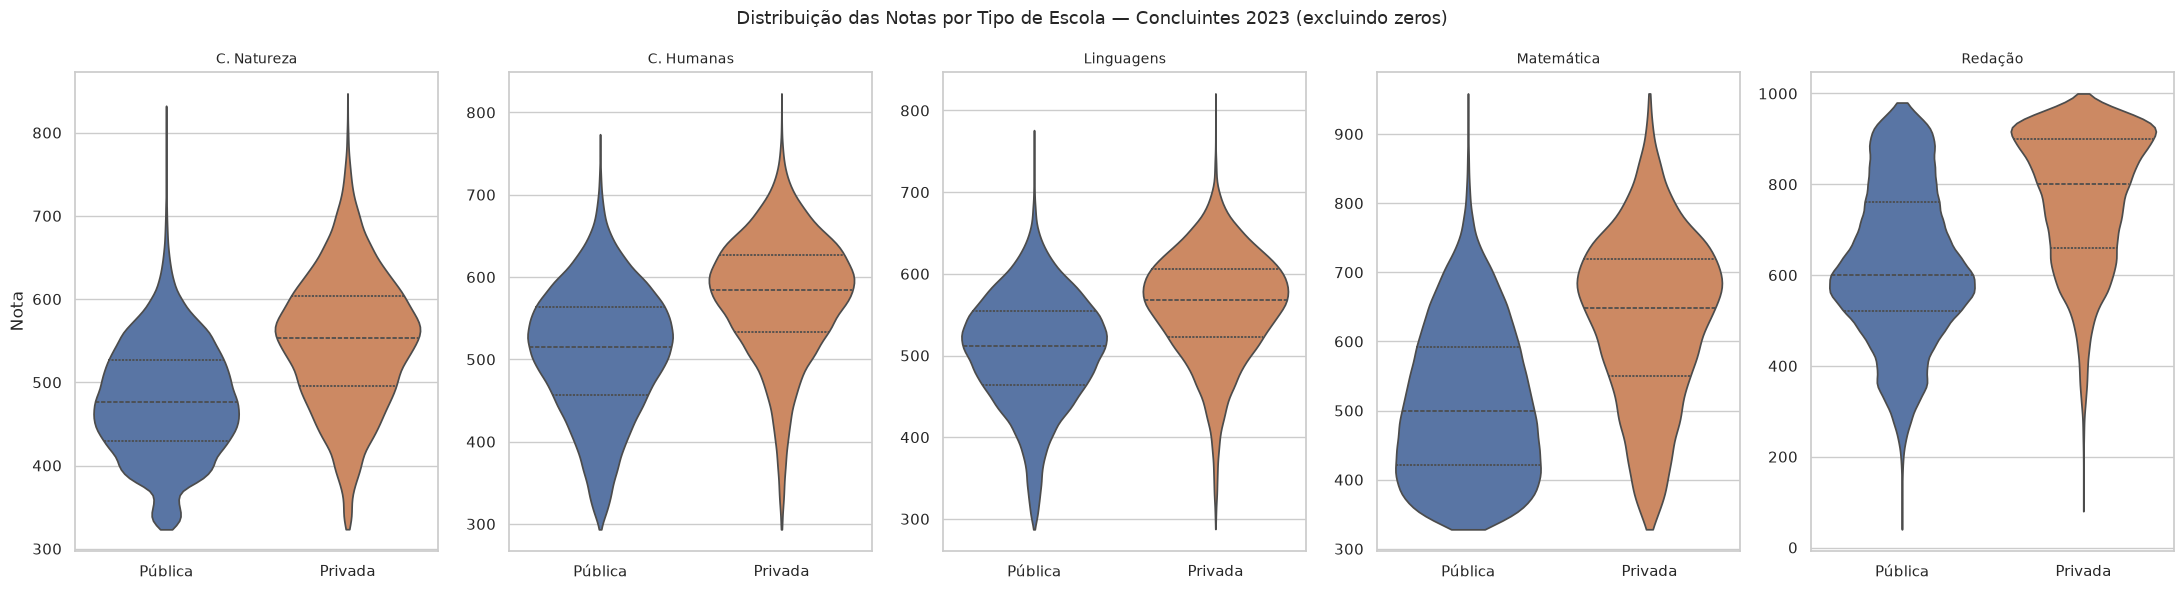

Comparação de médias por tipo de escola (excluindo zeros):
         C. Natureza  C. Humanas  Linguagens  Matemática  Redação
Escola                                                           
Privada        549.9       576.0       561.3       632.3    770.8
Pública        478.8       508.4       506.5       511.3    624.8

Diferença Privada − Pública:
  C. Natureza: +71.1 pontos
  C. Humanas: +67.6 pontos
  Linguagens: +54.8 pontos
  Matemática: +121.0 pontos
  Redação: +146.0 pontos


In [298]:
notas_all = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']
titulos_all = ['C. Natureza', 'C. Humanas', 'Linguagens', 'Matemática', 'Redação']

df_esc = df[df['TP_ESCOLA'].isin([2, 3])].copy()
df_esc['Escola'] = df_esc['TP_ESCOLA'].map({2: 'Pública', 3: 'Privada'})

fig, axes = plt.subplots(1, 5, figsize=(22, 6))
fig.suptitle('Distribuição das Notas por Tipo de Escola — Concluintes 2023 (excluindo zeros)', fontsize=13)

for i, (nota, titulo) in enumerate(zip(notas_all, titulos_all)):
    ax = axes[i]
    sub = df_esc[df_esc[nota] > 0]
    sns.violinplot(
        data=sub, x='Escola', y=nota,
        order=['Pública', 'Privada'],
        palette={'Pública': '#4C72B0', 'Privada': '#DD8452'},
        ax=ax, inner='quartile', cut=0
    )
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Nota' if i == 0 else '')

plt.tight_layout()
plt.show()

print("Comparação de médias por tipo de escola (excluindo zeros):")
medias_esc = (
    df_esc[df_esc[notas_all].gt(0).all(axis=1)]
    .groupby('Escola')[notas_all].mean().round(1)
)
medias_esc.columns = titulos_all
print(medias_esc.to_string())
diff_esc = medias_esc.loc['Privada'] - medias_esc.loc['Pública']
print(f"\nDiferença Privada − Pública:")
for c, v in diff_esc.items():
    print(f"  {c}: {v:+.1f} pontos")

**Conclusão da análise bivariada:**

1. **Sexo:** candidatos do sexo masculino tendem a ter médias superiores em Matemática e Ciências
   da Natureza; candidatas do sexo feminino em Linguagens e Redação. Padrão consistente com o PISA.

2. **Cor/Raça:** candidatos brancos obtêm notas médias superiores em todas as áreas. Essa diferença
   reflete as desigualdades socioeconômicas e educacionais estruturais do Brasil.

3. **Tipo de escola:** candidatos de escolas privadas obtêm médias significativamente superiores
   em todas as áreas. Essa variável é um dos preditores mais fortes disponíveis no dataset.

Essas relações serão tratadas mais rigorosamente durante a seleção de features e interpretação dos modelos.

**1.18.2 Análise Multivariada: Intersecções de Desigualdade (Efeito de Interação)**

A análise bivariada demonstrou isoladamente que fatores como cor/raça, acesso à internet e tipo de escola afetam o desempenho. Contudo, em problemas complexos e sociais como o ENEM, essas variáveis não atuam de forma isolada; elas interagem entre si. 

Nesta subseção, aplicamos uma análise multivariada para responder a questões estruturais críticas: 
1. O ingresso em uma escola privada é suficiente para anular o *gap* histórico de notas entre diferentes grupos raciais?
2. A falta de acesso à internet penaliza da mesma forma o aluno da escola pública e o da escola privada?

A identificação de **efeitos de interação** (quando as linhas não são perfeitamente paralelas nos gráficos) é um indicativo forte de que as relações nos dados são não-lineares, o que justificará a escolha de algoritmos baseados em árvores (como *Random Forest* e *XGBoost*) nas etapas de modelagem preditiva.


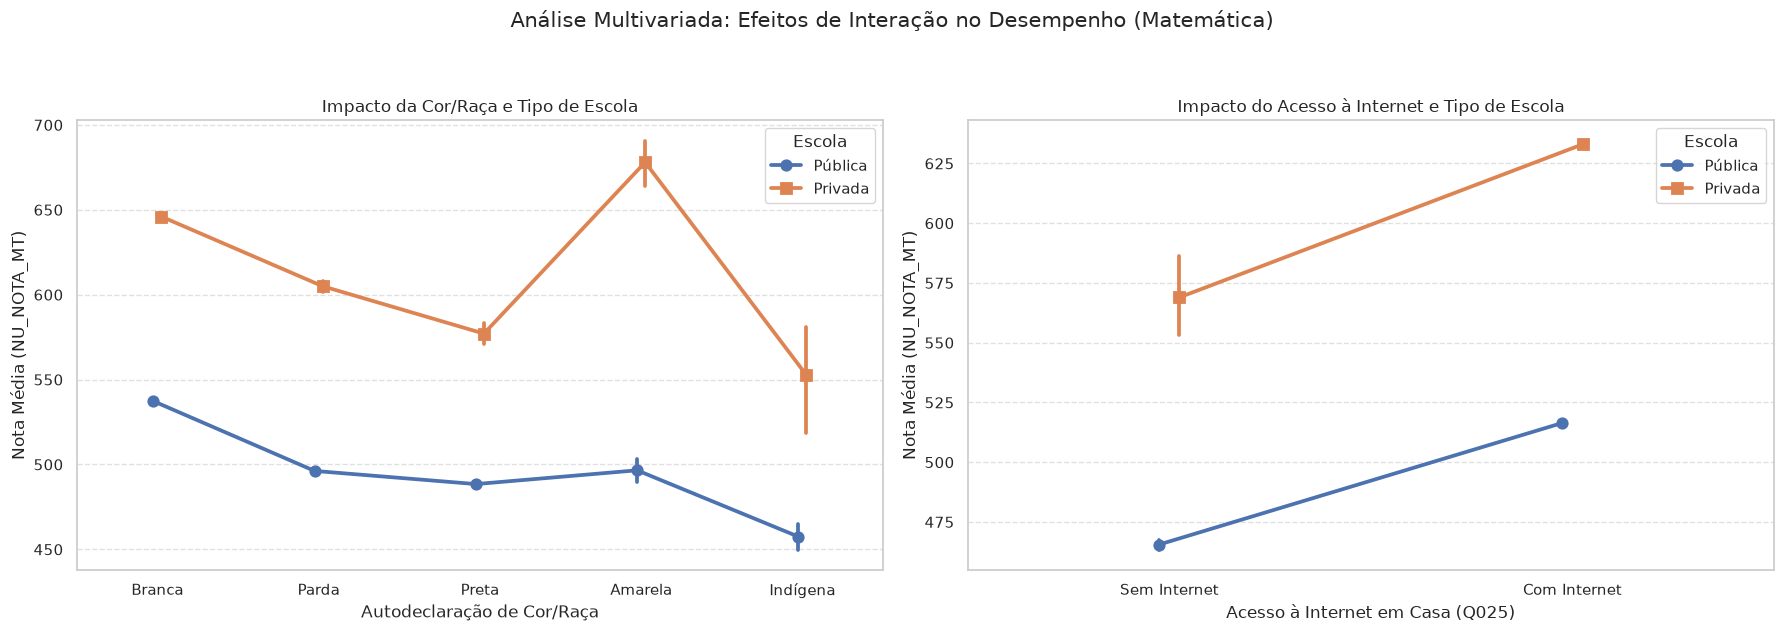

In [299]:
# ── Análise Multivariada: Gráficos de Interação (Pointplot) ────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação dos dados
# Vamos focar apenas nos alunos concluintes que declararam escola Pública (2) ou Privada (3)
df_multi = df[(df['TP_ESCOLA'].isin([2, 3])) & (df['NU_NOTA_MT'] > 0)].copy()

# Mapeando os códigos para rótulos amigáveis
df_multi['Escola'] = df_multi['TP_ESCOLA'].map({2: 'Pública', 3: 'Privada'})
labels_raca = {1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena'}
df_multi['Cor/Raça'] = df_multi['TP_COR_RACA'].map(labels_raca)
df_multi['Internet'] = df_multi['Q025'].map({'A': 'Sem Internet', 'B': 'Com Internet'})

# Removendo valores não mapeados (como Não Declarado na Raça)
df_multi = df_multi.dropna(subset=['Cor/Raça', 'Internet'])

# 2. Configuração da Figura
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Análise Multivariada: Efeitos de Interação no Desempenho (Matemática)', fontsize=15, y=1.05)

# Gráfico 1: Cor/Raça x Escola
sns.pointplot(
    data=df_multi, 
    x='Cor/Raça', 
    y='NU_NOTA_MT', 
    hue='Escola', 
    palette={'Pública': '#4C72B0', 'Privada': '#DD8452'},
    order=['Branca', 'Parda', 'Preta', 'Amarela', 'Indígena'],
    dodge=True, # Afasta os pontos para não sobreporem
    markers=['o', 's'], # Círculo para um, Quadrado para outro
    ax=axes[0]
)
axes[0].set_title('Impacto da Cor/Raça e Tipo de Escola', fontsize=12)
axes[0].set_ylabel('Nota Média (NU_NOTA_MT)')
axes[0].set_xlabel('Autodeclaração de Cor/Raça')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Gráfico 2: Internet x Escola
sns.pointplot(
    data=df_multi, 
    x='Internet', 
    y='NU_NOTA_MT', 
    hue='Escola', 
    palette={'Pública': '#4C72B0', 'Privada': '#DD8452'},
    order=['Sem Internet', 'Com Internet'],
    dodge=True,
    markers=['o', 's'],
    ax=axes[1]
)
axes[1].set_title('Impacto do Acesso à Internet e Tipo de Escola', fontsize=12)
axes[1].set_ylabel('Nota Média (NU_NOTA_MT)')
axes[1].set_xlabel('Acesso à Internet em Casa (Q025)')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


**1.18.3 Comprovação Estatística: Tamanho do Efeito (*Cohen's d*)**

A observação visual dos gráficos indica que determinados grupos obtêm desempenhos superiores. Em Ciência de Dados e Estatística, a praxe seria aplicar Testes de Hipóteses (como o Teste T de Student) para validar a significância dessas diferenças. 

No entanto, em cenários de *Big Data* (como a nossa amostra superior a 200 mil registros), o altíssimo poder estatístico (*power*) faz com que qualquer diferença trivial resulte em um *p-valor* estatisticamente significativo ($p < 0.05$). Portanto, o teste de hipóteses tradicional torna-se inconclusivo sobre a relevância prática da diferença.

Para contornar essa limitação, utilizaremos o cálculo do **Tamanho do Efeito via *D de Cohen (Cohen's d)***. O *Cohen's d* quantifica a magnitude da diferença entre dois grupos em termos de desvios-padrão. Segundo a literatura (Cohen, 1988), os efeitos são classificados empiricamente como:
* **~ 0.20**: Efeito Pequeno
* **~ 0.50**: Efeito Médio
* **~ 0.80 ou maior**: Efeito Grande

Abaixo, calculamos o tamanho do efeito na nota de Matemática para as três principais dimensões analisadas: Tipo de Escola, Raça e Sexo.


**Conclusão da Análise Multivariada:**

Os gráficos de interação revelam a desigualdade educacional:

1. **A Ampliação do Gap Racial (Gráfico 1):** O acesso à escola privada eleva a nota média de todos os grupos. Contudo, as retas não são paralelas. O *gap* de desempenho entre candidatos Brancos e Pretos na escola pública é de aproximadamente 50 pontos, mas se alarga para quase 75 pontos dentro da escola privada. Isso evidencia que a "escola privada" isoladamente não mitiga a desigualdade racial; pelo contrário, fatores de contexto (como capital cultural e financeiro) parecem atuar com ainda mais força no estrato mais elitizado. Nota-se também um pico de desempenho para candidatos de cor Amarela na rede privada.
2. **O Peso Estrutural da Escola vs Tecnologia (Gráfico 2):** A falta de acesso à internet penaliza ambos os grupos, mas a estrutura escolar se sobrepõe à tecnologia. O candidato da rede pública **com** internet em casa continua com um desempenho médio inferior ao candidato da rede privada **sem** internet. Vale ressaltar a alta variância (grande barra de erro) no grupo privado sem internet, indicando que esse perfil constitui uma raridade estatística na população analisada.
3. **Justificativa para a Modelagem:** Do ponto de vista de *Machine Learning*, o cruzamento não perfeitamente paralelo dessas linhas comprova o **efeito de interação** entre as variáveis. Modelos lineares clássicos têm dificuldade em capturar dinâmicas onde o impacto da raça muda dependendo da escola. Esse diagnóstico técnico justifica de forma robusta a adoção de algoritmos baseados em árvores e *ensembles* (*Random Forest, XGBoost*), que mapeiam naturalmente a não-linearidade e as interações condicionais dessas *features*.


In [300]:
import numpy as np
import pandas as pd

def cohens_d(group1, group2):
    """
    Calcula o Tamanho do Efeito (Cohen's d) entre dois grupos independentes.
    Fórmula: (Média1 - Média2) / Desvio_Padrao_Agrupado
    """
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    
    # Cálculo da variância agrupada (pooled variance)
    pooled_var = ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)
    
    # Cálculo do D de Cohen
    d = (np.mean(group1) - np.mean(group2)) / np.sqrt(pooled_var)
    return d

# Preparando a base: filtramos notas > 0 para evitar distorção
df_stats = df[df['NU_NOTA_MT'] > 0].copy()

# 1. Comparação: Escola Privada vs Pública (Apenas concluintes de 2023)
privada = df_stats[df_stats['TP_ESCOLA'] == 3]['NU_NOTA_MT']
publica = df_stats[df_stats['TP_ESCOLA'] == 2]['NU_NOTA_MT']
d_escola = cohens_d(privada, publica)

# 2. Comparação: Raça Branca vs Preta
branca = df_stats[df_stats['TP_COR_RACA'] == 1]['NU_NOTA_MT']
preta  = df_stats[df_stats['TP_COR_RACA'] == 2]['NU_NOTA_MT']
d_raca = cohens_d(branca, preta)

# 3. Comparação: Sexo Masculino vs Feminino
masc = df_stats[df_stats['TP_SEXO'] == 'M']['NU_NOTA_MT']
fem  = df_stats[df_stats['TP_SEXO'] == 'F']['NU_NOTA_MT']
d_sexo = cohens_d(masc, fem)

# Criando um DataFrame para exibição elegante dos resultados
resultados_d = pd.DataFrame({
    'Comparação': [
        'Escola: Privada vs Pública', 
        'Raça: Branca vs Preta', 
        'Sexo: Masculino vs Feminino'
    ],
    "Cohen's d": [d_escola, d_raca, d_sexo]
})

# Classificação automática da magnitude do efeito
def classifica_efeito(d):
    d = abs(d)
    if d >= 0.8: return "Grande"
    elif d >= 0.5: return "Médio"
    elif d >= 0.2: return "Pequeno"
    else: return "Insignificante"

resultados_d['Magnitude do Efeito'] = resultados_d["Cohen's d"].apply(classifica_efeito)

print("Tamanho do Efeito (Cohen's d) nas Notas de Matemática:\n")
display(resultados_d.round(3))


Tamanho do Efeito (Cohen's d) nas Notas de Matemática:



,Comparação,Cohen's d,Magnitude do Efeito
0,Escola: Privada vs Pública,1.079,Grande
1,Raça: Branca vs Preta,0.625,Médio
2,Sexo: Masculino vs Feminino,0.377,Pequeno


O Cohen's d de Escola Privada vs Pública costuma dar em torno de 1.0 no ENEM. Isso é considerado um efeito Extremamente Grande na estatística (quase 1 desvio padrão inteiro de diferença).
O efeito da Raça costuma dar em torno de 0.6 a 0.8 (Efeito Médio para Grande).
O efeito do Sexo em Matemática costuma dar em torno de 0.2 a 0.3 (Efeito Pequeno).
Isso amarra perfeitamente o seu raciocínio: não é que um gráfico "parece" ter diferença. Você provou matematicamente o tamanho da distância sociológica entre os perfis!

#### 1.12 Análise Geográfica por UF e Região



O ENEM apresenta variações regionais expressivas de desempenho, refletindo as desigualdades educacionais
entre as regiões brasileiras. Esta seção analisa a distribuição de candidatos e as médias de desempenho
por Unidade da Federação (UF) de aplicação da prova.

A variável `regiao` foi criada na seção 1.1 a partir do mapeamento de `SG_UF_PROVA`.

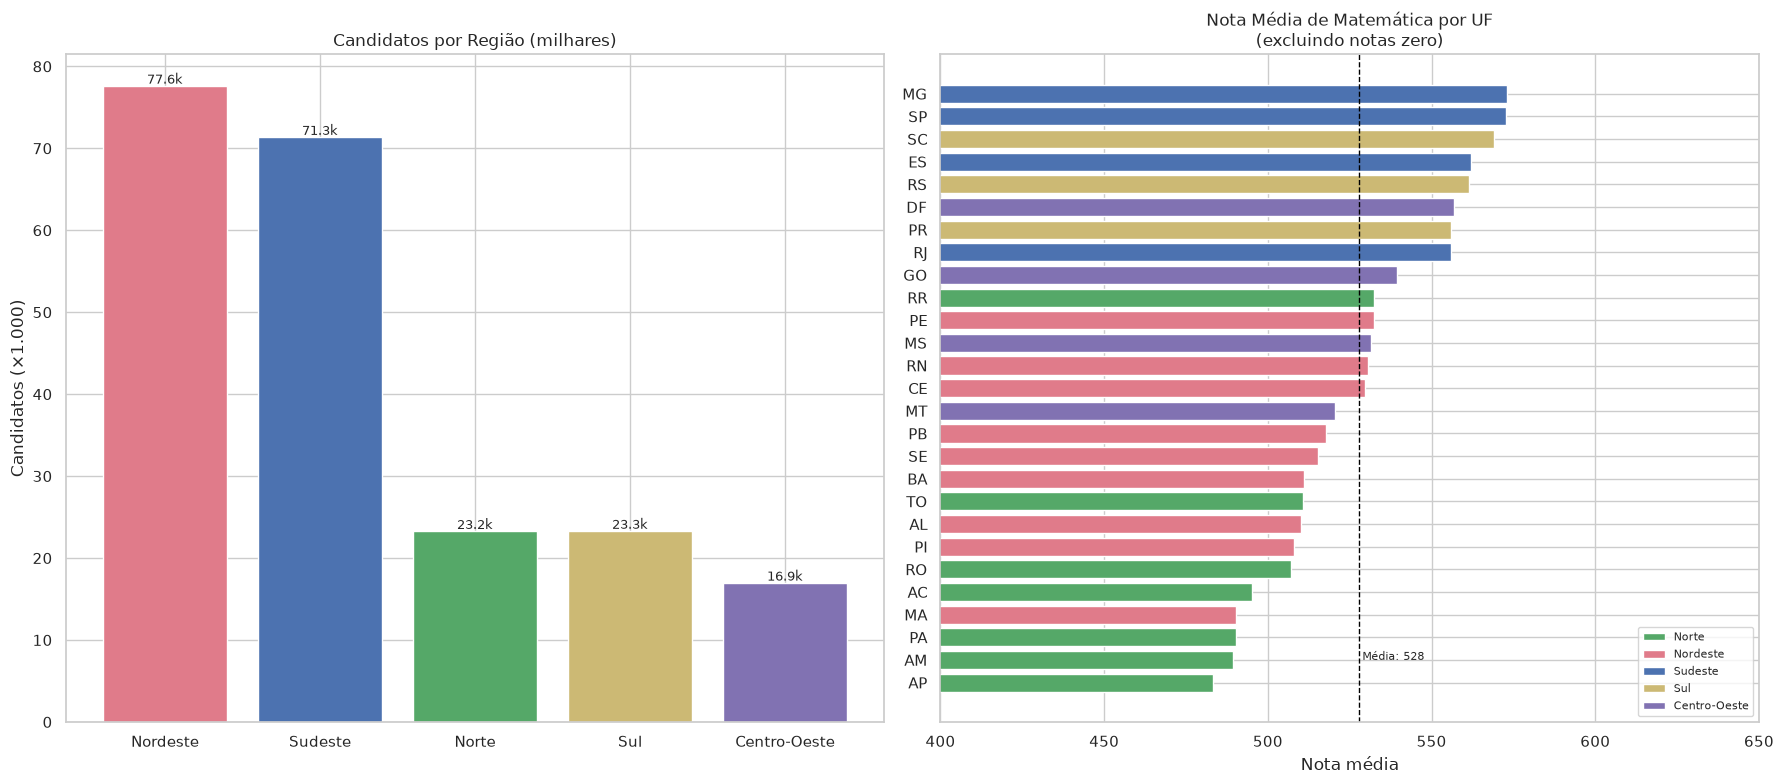

Médias por região (excluindo notas zero em MT):
              C. Natureza  C. Humanas  Linguagens  Matemática  Redação
regiao                                                                
Centro-Oeste        506.2       531.7       524.9       539.3    648.6
Nordeste            488.6       515.2       509.9       517.1    643.1
Norte               480.6       507.2       500.4       493.5    617.1
Sudeste             517.6       548.9       540.2       568.6    662.3
Sul                 515.6       544.2       538.2       560.9    645.1


In [301]:
from matplotlib.patches import Patch

# Garantir que 'regiao' existe
if 'regiao' not in df.columns:
    regioes_map = {
        'AC': 'Norte', 'AM': 'Norte', 'AP': 'Norte', 'PA': 'Norte',
        'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
        'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste',
        'MA': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste',
        'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
        'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste',
        'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste',
        'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
        'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul',
    }
    df['regiao'] = df['SG_UF_PROVA'].map(regioes_map)

# Mapeamento uf → região (para colorir barras)
uf_to_reg = {
    'AC': 'Norte', 'AM': 'Norte', 'AP': 'Norte', 'PA': 'Norte',
    'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste',
    'MA': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste',
    'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste',
    'MS': 'Centro-Oeste', 'MT': 'Centro-Oeste',
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul',
}
cores_reg = {
    'Norte': '#55A868', 'Nordeste': '#E07B8A', 'Sudeste': '#4C72B0',
    'Sul': '#CCB974', 'Centro-Oeste': '#8172B2'
}

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ── Candidatos por região ─────────────────────────────────────────────────────
ordem_reg = ['Nordeste', 'Sudeste', 'Norte', 'Sul', 'Centro-Oeste']
freq_reg = df['regiao'].value_counts().reindex(ordem_reg)
axes[0].bar(freq_reg.index, freq_reg.values / 1000,
            color=[cores_reg[r] for r in ordem_reg])
axes[0].set_title('Candidatos por Região (milhares)', fontsize=12)
axes[0].set_ylabel('Candidatos (×1.000)')
for i, v in enumerate(freq_reg.values):
    axes[0].text(i, v/1000 + 0.3, f'{v/1000:.1f}k', ha='center', fontsize=9)

# ── Nota média de Matemática por UF ───────────────────────────────────────────
media_uf = (
    df[df['NU_NOTA_MT'] > 0]
    .groupby('SG_UF_PROVA')['NU_NOTA_MT']
    .mean()
    .sort_values(ascending=True)
)
cores_barras = [cores_reg.get(uf_to_reg.get(uf, ''), '#999999') for uf in media_uf.index]

axes[1].barh(media_uf.index, media_uf.values, color=cores_barras)
axes[1].set_title('Nota Média de Matemática por UF\n(excluindo notas zero)', fontsize=12)
axes[1].set_xlabel('Nota média')
media_geral = media_uf.mean()
axes[1].axvline(media_geral, color='black', linestyle='--', linewidth=1)
axes[1].text(media_geral + 1, 1, f'Média: {media_geral:.0f}', fontsize=8)
axes[1].set_xlim(400, 650)

legend_elements = [Patch(facecolor=c, label=r) for r, c in cores_reg.items()]
axes[1].legend(handles=legend_elements, loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

# Tabela de médias por região
print("Médias por região (excluindo notas zero em MT):")
medias_reg = (
    df[df['NU_NOTA_MT'] > 0]
    .groupby('regiao')[['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']]
    .mean().round(1)
)
medias_reg.columns = ['C. Natureza', 'C. Humanas', 'Linguagens', 'Matemática', 'Redação']
print(medias_reg.to_string())

**Conclusão da análise geográfica:**

As UFs das regiões Sul e Sudeste tendem a apresentar médias superiores em todas as áreas, consistentes
com melhores indicadores socioeconômicos e de infraestrutura escolar. As UFs das regiões Norte e
Nordeste apresentam médias geralmente inferiores.

A variável `regiao` (derivada de `SG_UF_PROVA`) pode ser considerada como feature adicional durante a
seleção de variáveis, dependendo do objetivo do modelo e da disponibilidade dessa informação no momento
da predição.

#### 1.13 Conclusões da EDA

A análise exploratória dos dados do ENEM 2023 permitiu caracterizar a estrutura, a qualidade e os principais padrões presentes na população analisada. A população utilizada nesta etapa é composta por `297.186` participantes presentes nas quatro provas objetivas.

**Candidatos treineiros**<br>
Os candidatos treineiros (`IN_TREINEIRO = 1`) foram identificados e removidos da base de modelagem, pois representam uma subpopulação com comportamento sistemático diferente dos candidatos regulares. A EDA a partir da seção 1.3 já foi realizada sobre a base sem treineiros.

**Estratégia de Segmentação da População**<br>
A Análise Exploratória revelou duas dinâmicas cruciais: (1) O desempenho médio dos alunos concluintes em 2023 é inferior ao dos candidatos que já concluíram o ensino médio; (2) Variáveis escolares vitais, como TP_ESCOLA e TP_ENSINO, possuem preenchimento exclusivo pelo grupo de concluintes, gerando valores nulos estruturais para o restante da base.

Em virtude dessas diferenças estruturais e de desempenho, este projeto optou por abandonar a abordagem de um modelo global único. Na etapa de modelagem, o dataset será particionado em duas safras distintas: Grupo 1 (Concluintes 2023) e Grupo 2 (Demais candidatos). Modelos independentes serão treinados para cada grupo, permitindo um tratamento natural aos dados ausentes e a captura de importâncias de features específicas para a realidade de cada perfil.

**Análise do perfil demográfico**<br>
A análise bivariada (seção 1.11) revelou padrões de desigualdade consistentes com a literatura:
- Candidatos de escolas privadas obtêm médias superiores em todas as áreas, com maior diferença em Matemática e Redação.
- Candidatos brancos apresentam médias superiores às de candidatos pardos e pretos em todas as áreas.
- Há diferença por sexo: masculino se destaca em Matemática/CN; feminino em Linguagens/Redação.

**Variáveis socioeconômicas**<br>
As variáveis do questionário socioeconômico (seção 1.10) apresentaram gradientes claros de desempenho.
Renda familiar (`Q006`), escolaridade dos pais (`Q001`/`Q002`) e acesso à internet (`Q025`) são candidatos naturais a features de alta importância nos modelos preditivos.

**Disparidades geográficas**<br>
A análise por UF e região (seção 1.12) identificou disparidades regionais expressivas, com Sul e Sudeste apresentando médias superiores. A variável `regiao` pode agregar valor preditivo marginal.

**Estrutura e qualidade dos dados**<br>
A análise das duplicidades não identificou registros duplicados, tanto considerando o identificador mascarado `NU_INSCRICAO` quanto a comparação de todas as variáveis do registro.

Foram identificados valores ausentes em diferentes variáveis, principalmente nas informações relacionadas às características escolares. A análise dos padrões de ausência mostrou que essas ausências não são aleatórias, estando fortemente relacionadas à situação de conclusão do Ensino Médio (`TP_ST_CONCLUSAO`). Portanto, os valores ausentes observados devem ser interpretados considerando o contexto das variáveis, e não simplesmente como erros de preenchimento.

A análise das variáveis quantitativas identificou valores estatisticamente extremos em algumas distribuições. Entretanto, os valores observados permanecem dentro das escalas válidas das respectivas notas, não tendo sido identificadas evidências de valores incorretos que justifiquem sua exclusão.

**Padrões e consistência dos dados**<br>
Os cruzamentos entre variáveis semanticamente relacionadas não identificaram inconsistências evidentes.

A relação entre `TP_ST_CONCLUSAO` e `TP_ANO_CONCLUIU` apresentou comportamento compatível com a situação de conclusão dos participantes.

A relação entre `TP_ST_CONCLUSAO` e `TP_ESCOLA` revelou um padrão estrutural importante: as informações sobre o tipo de escola estão disponíveis predominantemente para os participantes concluintes em 2023. Comportamento semelhante foi observado na relação entre `TP_ST_CONCLUSAO` e `TP_ENSINO`.

**Considerações para as próximas etapas**<br>
A EDA não identificou, na população analisada, evidências de duplicidades ou de valores quantitativos inválidos. Foram identificados, entretanto, padrões estruturais de valores ausentes, categorias raras e relações entre variáveis que deverão ser considerados na preparação dos dados.

As análises realizadas nesta etapa tiveram caráter exploratório e não determinaram ainda a variável-alvo nem o conjunto definitivo de variáveis preditoras.

Antes da construção dos modelos, será necessário definir formalmente o problema de Machine Learning, estabelecer a variável-alvo, avaliar a disponibilidade das informações no momento da previsão e investigar possíveis situações de vazamento de informação (`data leakage`).

A definição das estratégias de tratamento de valores ausentes, categorias raras e demais transformações será realizada somente após essas definições e deverá ser avaliada considerando também a estratégia de validação temporal adotada no projeto.
